# Assignment 2: Detecting emotions with ML algorithms

## 1. FER2013 Baseline (20%)

### 1.1 Setup and experimental protocol
We adapt `z_load_split_fer2013.ipynb` for loading and
`baseline_fer2013_landmarks.ipynb` for the landmark + Random Forest baseline.

We compare all nine combinations of three feature types and three classifiers.
Training fits every learned transformation and classifier; PublicTest selects the
configuration by macro-F1 (balanced accuracy breaks ties). PrivateTest is used
only after the configurations are frozen. No augmentation, balancing, or extensive
tuning is applied here, leaving improvement experiments for Task 5.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import sys
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dlib
import joblib
from IPython.display import display
from skimage.feature import hog
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
ROOT = Path.cwd()
assert (ROOT / 'emotion_detection_group11.ipynb').exists(), 'Run from the repository folder.'
DATA = ROOT / 'data'
CSV = next((p for p in [DATA / 'fer2013.csv', DATA / 'fer' / 'fer2013.csv'] if p.exists()), None)
if CSV is None:
    raise FileNotFoundError('Place fer2013.csv in data/ or data/fer/.')
PREDICTOR = ROOT / 'faceAndLandmarkModels' / 'shape_predictor_68_face_landmarks_GTX.dat'
assert PREDICTOR.exists(), f'Missing landmark predictor: {PREDICTOR}'
OUT = ROOT / 'results' / 'task1'
CACHE = DATA / 'feature_cache' / 'task1'
MODEL_DIR = ROOT / 'models' / 'task1'
for folder in [OUT, CACHE, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
EMOTIONS = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
LABELS = np.arange(7)
plt.rcParams.update({'figure.dpi': 110})
print('Python:', sys.executable)
print('Dataset:', CSV.relative_to(ROOT))

Python: /opt/anaconda3/envs/emotion-detection/bin/python
Dataset: data/fer2013.csv


### 1.2 Load the official splits and inspect training data
Keep Training, PublicTest, and PrivateTest separate, exactly as in the supplied
loading notebook. Each image must contain 2,304 integer pixels between 0 and 255.
The test pixels remain unprocessed until final evaluation.

,split,images
0,train,28709
1,validation,3589
2,test,3589


,emotion,training_images
0,Angry,3995
1,Disgust,436
2,Fear,4097
3,Happy,7215
4,Sad,4830
5,Surprise,3171
6,Neutral,4965


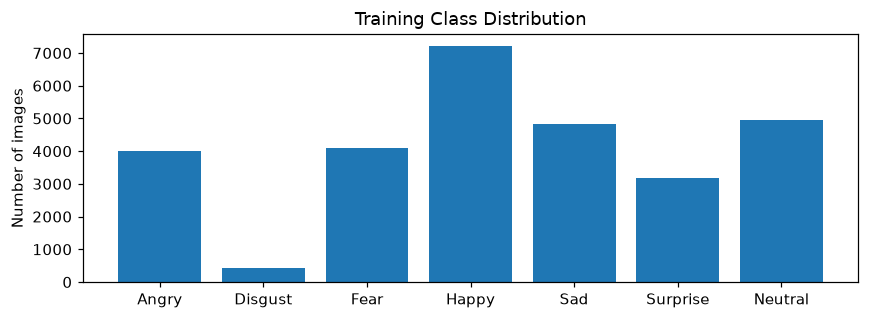

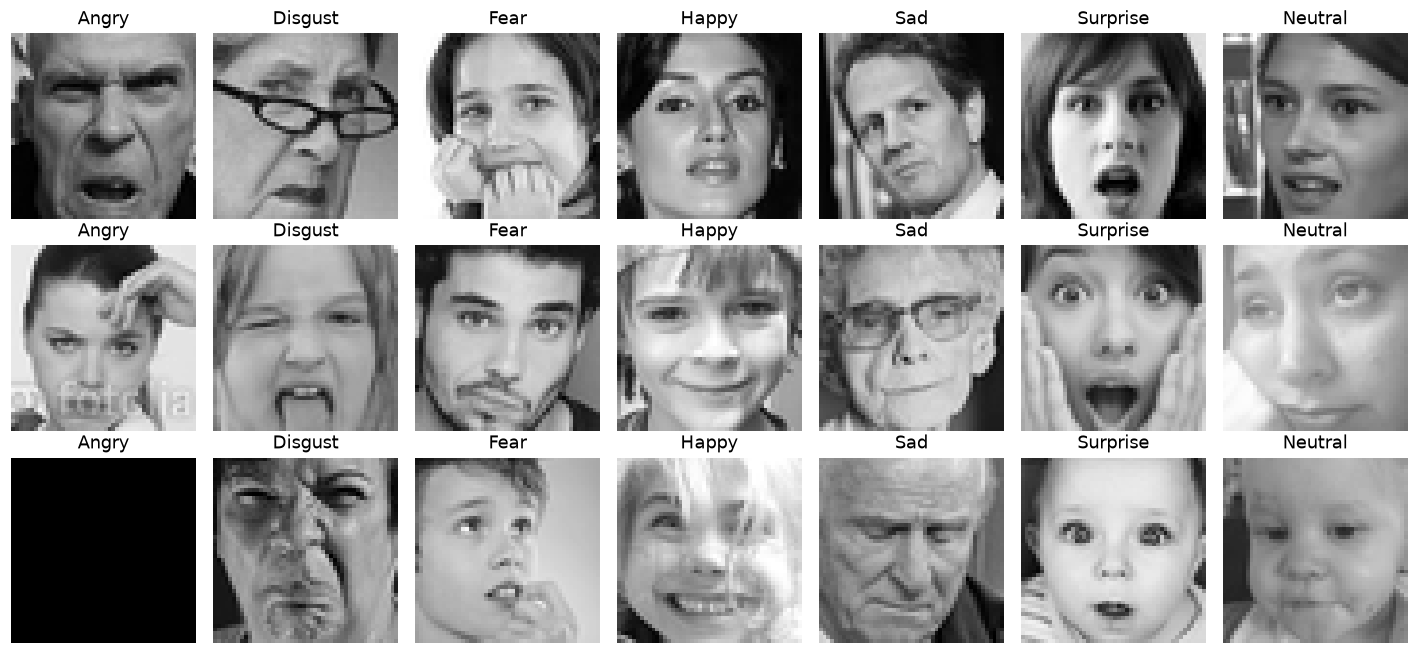

In [31]:
df = pd.read_csv(CSV)
assert {'emotion', 'pixels', 'Usage'}.issubset(df.columns)
assert not df[['emotion', 'pixels', 'Usage']].isna().any().any()
assert set(df['emotion'].unique()) == set(LABELS)
assert set(df['Usage'].unique()) == {'Training', 'PublicTest', 'PrivateTest'}
split_frames = {
    'train': df.loc[df.Usage == 'Training'].reset_index(drop=True),
    'validation': df.loc[df.Usage == 'PublicTest'].reset_index(drop=True),
    'test': df.loc[df.Usage == 'PrivateTest'].reset_index(drop=True),
}
display(pd.DataFrame({'split': split_frames.keys(),
                      'images': [len(frame) for frame in split_frames.values()]}))

def decode_images(frame):
    rows = [np.fromstring(s, sep=' ', dtype=np.int32) for s in frame['pixels']]
    if any(row.size != 48 * 48 for row in rows):
        raise ValueError('An image does not contain 2304 pixels.')
    pixels = np.stack(rows)
    assert pixels.min() >= 0 and pixels.max() <= 255
    return pixels.astype(np.uint8).reshape(-1, 48, 48)

images = {split: decode_images(split_frames[split]) for split in ['train', 'validation']}
y = {split: frame.emotion.to_numpy(dtype=int) for split, frame in split_frames.items()}

def plot_class_distribution(targets, title):
    counts = pd.Series(targets).value_counts().reindex(LABELS)
    display(pd.DataFrame({'emotion': EMOTIONS, 'training_images': counts.to_numpy()}))
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.bar(EMOTIONS, counts.to_numpy())
    ax.set(title=title, ylabel='Number of images')
    plt.tight_layout()
    plt.show()

plot_class_distribution(y["train"], "Training Class Distribution")

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 7, figsize=(13, 6))
for label in LABELS:
    indices = rng.choice(np.flatnonzero(y['train'] == label), size=3, replace=False)
    for row, index in enumerate(indices):
        axes[row, label].imshow(images['train'][index], cmap='gray', vmin=0, vmax=255)
        axes[row, label].set_title(EMOTIONS[label])
        axes[row, label].axis('off')
plt.tight_layout()
plt.show()

### 1.3 Check and extract the supplied facial landmarks
FER images are already face crops, so the starter uses a fixed rectangle rather
than a face detector. We retain its rectangle and normalization: center the 68
points and scale each coordinate axis by its largest absolute value, yielding
136 features. A small denominator guard prevents division by zero.

Inspect the overlays: a predictor always returns points, but they may be inaccurate
on low-resolution, occluded, or rotated faces. Input to dlib stays uint8 in [0,255].

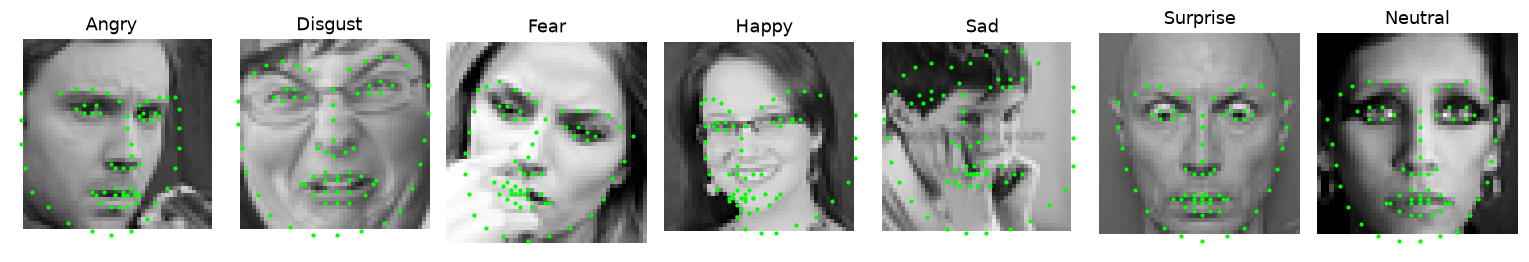

Extracted landmarks/train: (28709, 136), 13.7s
Extracted landmarks/validation: (3589, 136), 1.8s


In [3]:
landmark_predictor = dlib.shape_predictor(str(PREDICTOR))
face_rect = dlib.rectangle(left=1, top=1, right=47, bottom=47)

def landmark_points(image):
    shape = landmark_predictor(np.ascontiguousarray(image, dtype=np.uint8), face_rect)
    return np.array([(p.x, p.y) for p in shape.parts()], dtype=np.float32)

def extract_landmarks(batch):
    features = []
    for image in batch:
        points = landmark_points(image)
        points -= points.mean(axis=0, keepdims=True)
        points /= np.maximum(np.abs(points).max(axis=0, keepdims=True), 1e-8)
        features.append(points.ravel())
    return np.stack(features)

fig, axes = plt.subplots(1, 7, figsize=(14, 3))
for label, ax in enumerate(axes):
    index = np.flatnonzero(y['train'] == label)[0]
    image = images['train'][index]
    points = landmark_points(image)
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.scatter(points[:, 0], points[:, 1], s=3, c='lime')
    ax.set_title(EMOTIONS[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

# Cache keys include the input rows, extraction settings, and predictor contents.
dataset_hash = hashlib.sha256(CSV.read_bytes()).hexdigest()
predictor_hash = hashlib.sha256(PREDICTOR.read_bytes()).hexdigest()
HOG_SETTINGS = dict(orientations=9, pixels_per_cell=(8, 8),
                    cells_per_block=(2, 2), block_norm='L2-Hys', transform_sqrt=True)

def cached_features(kind, split, batch):
    settings = {'version': 1, 'dataset': dataset_hash, 'kind': kind, 'split': split,
                'predictor': predictor_hash if kind == 'landmarks' else None,
                'hog': HOG_SETTINGS if kind == 'hog' else None,
                'skimage': importlib.metadata.version('scikit-image'),
                'dlib': dlib.__version__}
    key = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:16]
    file = CACHE / f'{kind}_{split}_{key}.npy'
    if file.exists():
        result = np.load(file)
        print('Loaded:', file.name)
    else:
        start = perf_counter()
        if kind == 'landmarks':
            result = extract_landmarks(batch)
        elif kind == 'hog':
            result = np.stack([hog(image.astype(np.float32) / 255.0, **HOG_SETTINGS)
                               for image in batch]).astype(np.float32)
        else:
            raise ValueError(kind)
        np.save(file, result)
        print(f'Extracted {kind}/{split}: {result.shape}, {perf_counter()-start:.1f}s')
    assert result.shape[0] == len(batch) and np.isfinite(result).all()
    return result

features = {'landmarks': {
    split: cached_features('landmarks', split, images[split])
    for split in ['train', 'validation']
}}

### 1.4 Reproduce Random Forest + landmarks
These are the supplied settings: 300 trees, maximum depth 11, sqrt feature
sampling, entropy criterion, seed 42, and no class weighting. The starter computes
class weights but does not apply them. Its stored validation scores are approximately
0.44 accuracy, 0.37 balanced accuracy, and 0.38 macro-F1; our run is the evidence
used here. Small library-version differences can affect the scores.

,accuracy,balanced_accuracy,macro_f1
Provided RF + landmarks,0.444692,0.371654,0.375277


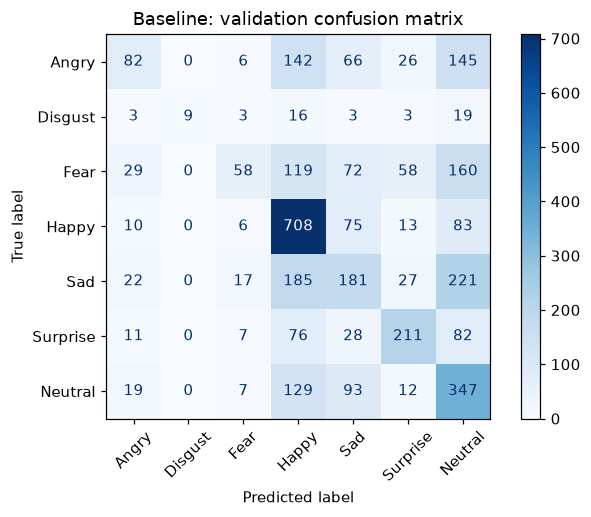

In [4]:
def new_random_forest():
    return RandomForestClassifier(n_estimators=300, max_depth=11,
                                  max_features='sqrt', criterion='entropy',
                                  random_state=SEED, n_jobs=-1)

def metric_scores(actual, predicted):
    return {'accuracy': accuracy_score(actual, predicted),
            'balanced_accuracy': balanced_accuracy_score(actual, predicted),
            'macro_f1': f1_score(actual, predicted, labels=LABELS,
                                 average='macro', zero_division=0)}

baseline_rf = new_random_forest()
start = perf_counter()
baseline_rf.fit(features['landmarks']['train'], y['train'])
baseline_fit_seconds = perf_counter() - start
baseline_predictions = baseline_rf.predict(features['landmarks']['validation'])
display(pd.DataFrame([metric_scores(y['validation'], baseline_predictions)],
                     index=['Provided RF + landmarks']))
ConfusionMatrixDisplay.from_predictions(y['validation'], baseline_predictions,
    labels=LABELS, display_labels=EMOTIONS, cmap='Blues', xticks_rotation=45)
plt.title('Baseline: validation confusion matrix')
plt.tight_layout()
plt.show()

### 1.5 HOG and PCA feature representations
HOG uses 9 orientations, 8×8 pixel cells, and 2×2 cell blocks: 900 features.
PCA uses 150 components of flattened pixels scaled to [0,1]. PCA centers the input
and is fitted on training images only; validation images only call `transform`.
These are fixed baseline choices, not test-selected parameters.

Extracted hog/train: (28709, 900), 5.8s
Extracted hog/validation: (3589, 900), 0.7s
PCA fit/transform: 1.5s
Variance retained: 92.3%


,feature,train_shape,validation_shape
0,landmarks,"(28709, 136)","(3589, 136)"
1,hog,"(28709, 900)","(3589, 900)"
2,pca,"(28709, 150)","(3589, 150)"


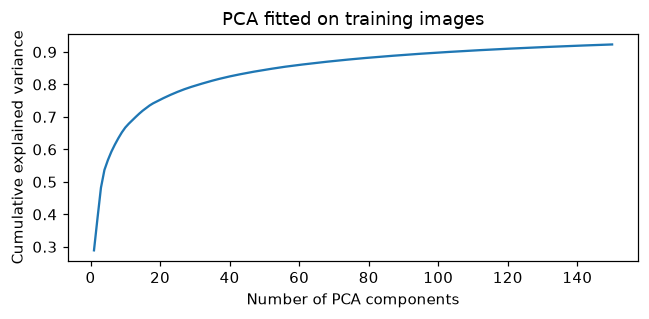

In [5]:
features['hog'] = {split: cached_features('hog', split, images[split])
                   for split in ['train', 'validation']}

def pixel_vectors(batch):
    return batch.reshape(len(batch), -1).astype(np.float32) / 255.0

pca = PCA(n_components=150, svd_solver='randomized', random_state=SEED)
start = perf_counter()
features['pca'] = {'train': pca.fit_transform(pixel_vectors(images['train']))}
features['pca']['validation'] = pca.transform(pixel_vectors(images['validation']))
print(f'PCA fit/transform: {perf_counter()-start:.1f}s')
print(f'Variance retained: {pca.explained_variance_ratio_.sum():.1%}')
display(pd.DataFrame([
    {'feature': name, 'train_shape': arrays['train'].shape,
     'validation_shape': arrays['validation'].shape}
    for name, arrays in features.items()]))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, 151), np.cumsum(pca.explained_variance_ratio_))
ax.set(xlabel='Number of PCA components', ylabel='Cumulative explained variance',
       title='PCA fitted on training images')
plt.tight_layout()
plt.show()

### 1.6 Train the nine configurations and compare validation scores
Logistic Regression and linear SVM use StandardScaler fitted inside their training
pipelines. Random Forest uses the feature vectors directly. LinearSVC is a linear
support vector machine; this experiment does not evaluate an RBF kernel.
We reuse the baseline forest rather than fitting the identical configuration twice.
The table records classifier fit time; shared feature extraction/PCA time is printed
above and is not included in that column. Convergence warnings should be resolved
before interpreting a run.

landmarks + Logistic Regression: macro-F1=0.3506
landmarks + Linear SVM: macro-F1=0.3040
landmarks + Random Forest: macro-F1=0.3753
hog + Logistic Regression: macro-F1=0.4000
hog + Linear SVM: macro-F1=0.3880
hog + Random Forest: macro-F1=0.3866
pca + Logistic Regression: macro-F1=0.2919
pca + Linear SVM: macro-F1=0.2712
pca + Random Forest: macro-F1=0.2916


,feature,classifier,accuracy,balanced_accuracy,macro_f1,fit_seconds
0,hog,Logistic Regression,0.4363,0.4021,0.4000,4.7024
1,hog,Linear SVM,0.4478,0.3836,0.3880,61.5835
2,hog,Random Forest,0.4483,0.3734,0.3866,26.4425
3,landmarks,Random Forest,0.4447,0.3717,0.3753,7.8818
4,landmarks,Logistic Regression,0.4313,0.3565,0.3506,2.3806
5,landmarks,Linear SVM,0.4238,0.3346,0.3040,7.1218
6,pca,Logistic Regression,0.3870,0.3040,0.2919,0.1113
7,pca,Random Forest,0.3759,0.2930,0.2916,11.5157
8,pca,Linear SVM,0.3831,0.2955,0.2712,0.9994


Selected using validation macro-F1: ('hog', 'Logistic Regression')


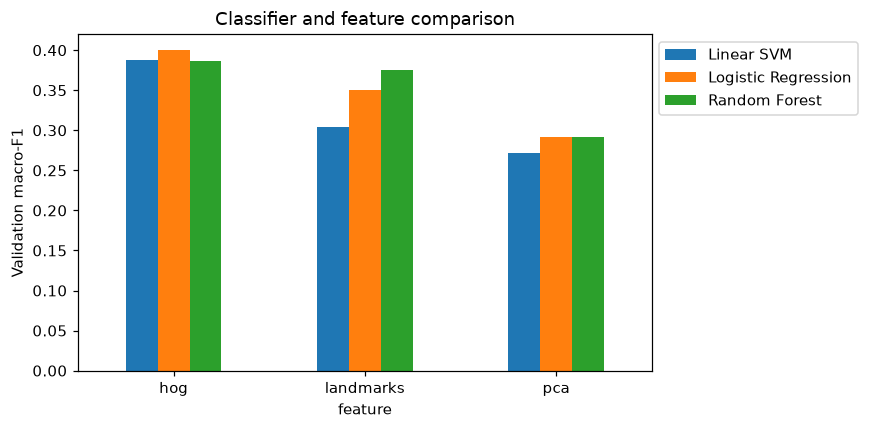

In [6]:
def new_classifier(name):
    if name == 'Logistic Regression':
        return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000,
                                                                  random_state=SEED))
    if name == 'Linear SVM':
        return make_pipeline(StandardScaler(), LinearSVC(C=0.01, dual=False,
                                                         max_iter=10000, random_state=SEED))
    if name == 'Random Forest':
        return new_random_forest()
    raise ValueError(name)

models, validation_predictions, rows = {}, {}, []
for feature_name, arrays in features.items():
    for classifier_name in ['Logistic Regression', 'Linear SVM', 'Random Forest']:
        key = (feature_name, classifier_name)
        if key == ('landmarks', 'Random Forest'):
            model, fit_seconds = baseline_rf, baseline_fit_seconds
        else:
            model = new_classifier(classifier_name)
            start = perf_counter()
            model.fit(arrays['train'], y['train'])
            fit_seconds = perf_counter() - start
        predictions = model.predict(arrays['validation'])
        models[key] = model
        validation_predictions[key] = predictions
        rows.append({'feature': feature_name, 'classifier': classifier_name,
                     **metric_scores(y['validation'], predictions),
                     'fit_seconds': fit_seconds})
        print(f'{feature_name} + {classifier_name}: macro-F1={rows[-1]["macro_f1"]:.4f}', flush=True)

validation_results = pd.DataFrame(rows).sort_values(
    ['macro_f1', 'balanced_accuracy'], ascending=False).reset_index(drop=True)
validation_results.to_csv(OUT / 'validation_results.csv', index=False)
display(validation_results.round(4))
best_key = tuple(validation_results.loc[0, ['feature', 'classifier']])
best_feature, best_classifier = best_key
print('Selected using validation macro-F1:', best_key)

fig, ax = plt.subplots(figsize=(8, 4))
validation_results.pivot(index='feature', columns='classifier', values='macro_f1').plot.bar(ax=ax)
ax.set(ylabel='Validation macro-F1', title='Classifier and feature comparison')
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(OUT / 'validation_comparison.png', bbox_inches='tight')
plt.show()

### 1.7 Validation error analysis for the selected configuration
Rows are actual emotions and columns predicted emotions. Row-normalized matrices
show class recall and make minority-class failures easier to see. The example
gallery is validation-only: inspect lighting, pose, occlusion, and ambiguous labels
without assuming that a wrong prediction proves a mislabeled image.

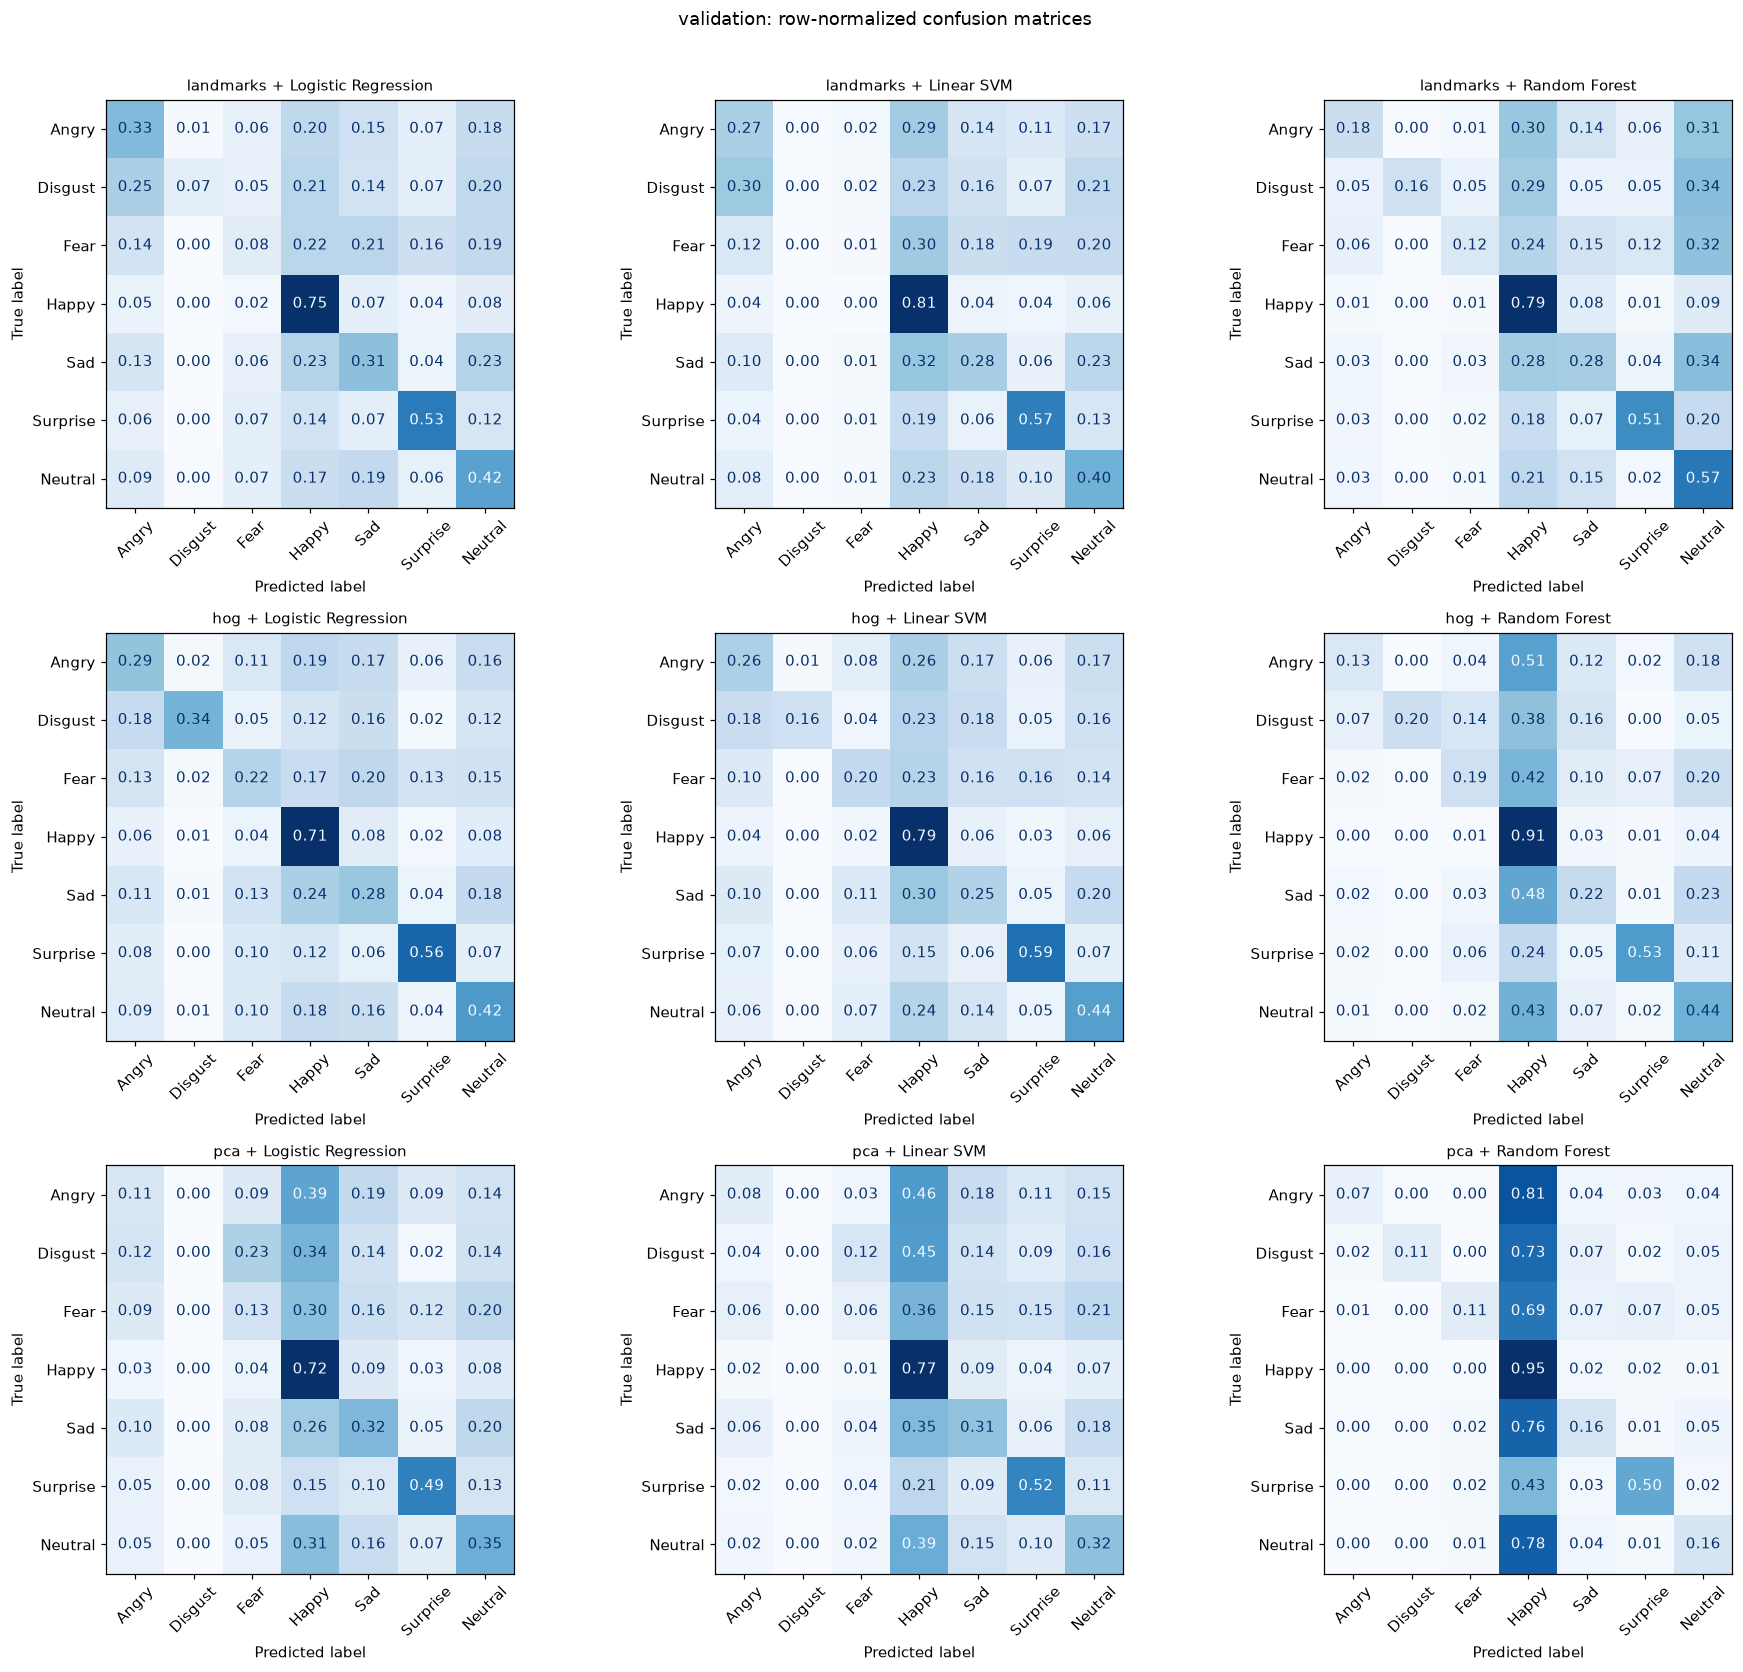

,precision,recall,f1-score,support
Angry,0.3221,0.2869,0.3035,467.0000
Disgust,0.3455,0.3393,0.3423,56.0000
Fear,0.2741,0.2177,0.2427,496.0000
Happy,0.5629,0.7095,0.6278,895.0000
Sad,0.3186,0.2757,0.2956,653.0000
Surprise,0.5865,0.5639,0.5749,415.0000
Neutral,0.4051,0.4217,0.4132,607.0000
accuracy,0.4363,0.4363,0.4363,0.4363
macro avg,0.4021,0.4021,0.4000,3589.0000
weighted avg,0.4199,0.4363,0.4251,3589.0000


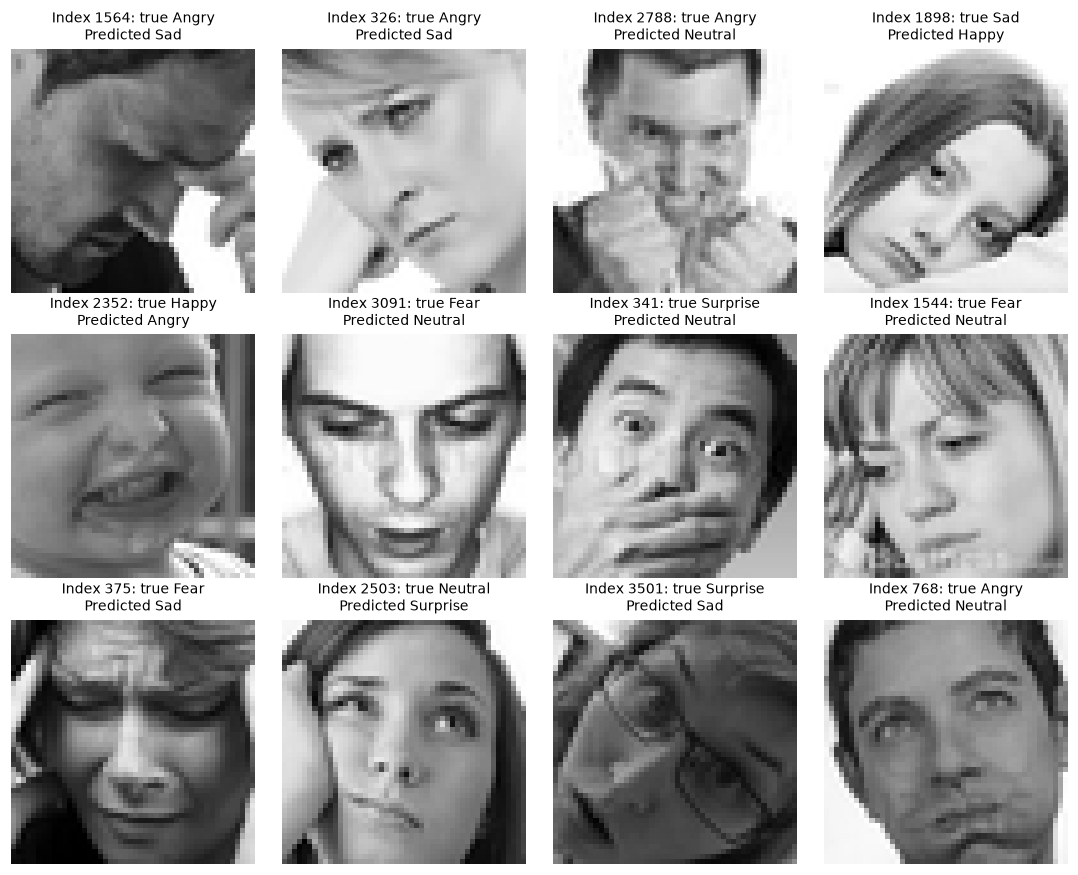

In [7]:
def plot_confusion_grid(predictions_by_model, actual, split):
    fig, axes = plt.subplots(3, 3, figsize=(17, 15))
    for ax, (key, predicted) in zip(axes.flat, predictions_by_model.items()):
        ConfusionMatrixDisplay.from_predictions(actual, predicted, labels=LABELS,
            display_labels=EMOTIONS, normalize='true', cmap='Blues',
            values_format='.2f', colorbar=False, ax=ax, xticks_rotation=45)
        ax.set_title(f'{key[0]} + {key[1]}', fontsize=10)
    fig.suptitle(f'{split}: row-normalized confusion matrices', y=1.01)
    plt.tight_layout()
    fig.savefig(OUT / f'{split}_confusion_matrices.png', bbox_inches='tight')
    plt.show()

plot_confusion_grid(validation_predictions, y['validation'], 'validation')
best_val_pred = validation_predictions[best_key]
validation_class_report = pd.DataFrame(classification_report(
    y['validation'], best_val_pred, labels=LABELS, target_names=EMOTIONS,
    output_dict=True, zero_division=0)).T
display(validation_class_report.round(4))
validation_class_report.to_csv(OUT / 'selected_validation_classification_report.csv')
mistakes = np.flatnonzero(best_val_pred != y['validation'])
chosen = np.random.default_rng(SEED).choice(mistakes, size=min(12, len(mistakes)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax in axes.flat:
    ax.axis('off')
for ax, index in zip(axes.flat, chosen):
    ax.imshow(images['validation'][index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Index {index}: true {EMOTIONS[y["validation"][index]]}\n'
                 f'Predicted {EMOTIONS[best_val_pred[index]]}', fontsize=9)
plt.tight_layout()
fig.savefig(OUT / 'validation_mistakes.png', bbox_inches='tight')
plt.show()

### 1.8 Freeze configurations, then evaluate PrivateTest
All nine configurations and the overall winner are now fixed using validation data.
We save that decision before evaluating PrivateTest. For a consistent comparison,
the models remain fitted on Training only (no train + validation refit).
Test results describe these fixed models; they must not change the selected winner
or trigger further tuning. The same nine configurations are reported on both splits.

Extracted landmarks/test: (3589, 136), 1.7s
Extracted hog/test: (3589, 900), 0.7s


,feature,classifier,accuracy,balanced_accuracy,macro_f1,selected_on_validation
0,landmarks,Logistic Regression,0.4500,0.3848,0.3843,False
1,landmarks,Linear SVM,0.4397,0.3515,0.3227,False
2,landmarks,Random Forest,0.4556,0.3898,0.3947,False
3,hog,Logistic Regression,0.4327,0.4040,0.3973,True
4,hog,Linear SVM,0.4369,0.3727,0.3726,False
5,hog,Random Forest,0.4558,0.3821,0.3971,False
6,pca,Logistic Regression,0.3720,0.2988,0.2892,False
7,pca,Linear SVM,0.3667,0.2877,0.2632,False
8,pca,Random Forest,0.3706,0.2907,0.2923,False


Final test scores of the validation-selected model:


,feature,classifier,accuracy,balanced_accuracy,macro_f1,selected_on_validation
3,hog,Logistic Regression,0.4327,0.404,0.3973,True


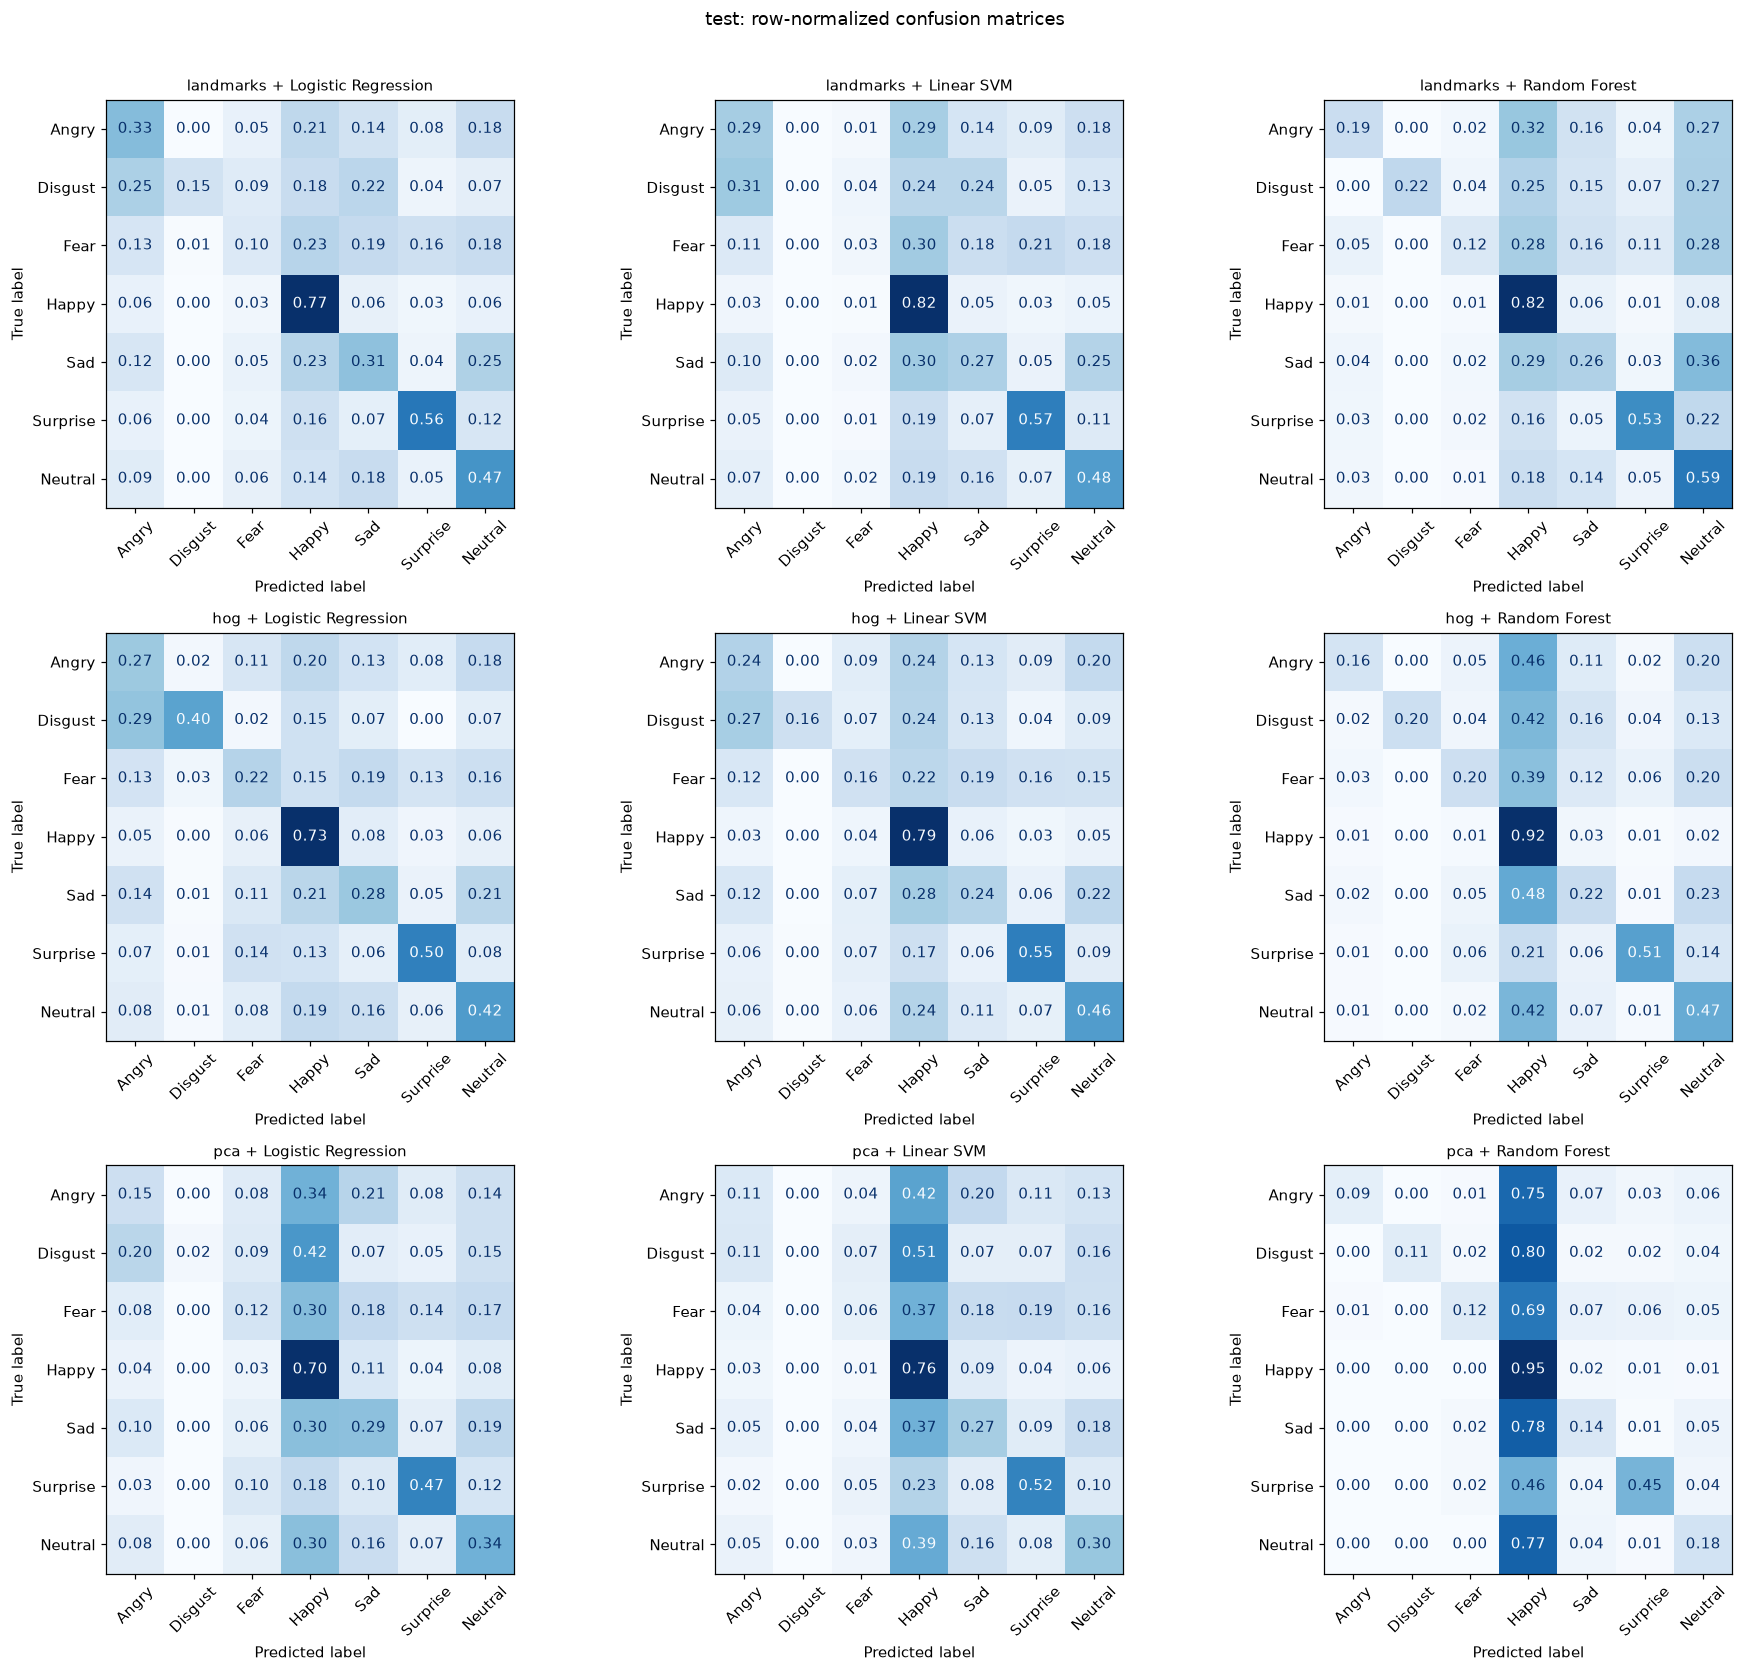

,precision,recall,f1-score,support
Angry,0.3162,0.2749,0.2941,491.0000
Disgust,0.3548,0.4000,0.3761,55.0000
Fear,0.2947,0.2216,0.2530,528.0000
Happy,0.5719,0.7281,0.6406,879.0000
Sad,0.3118,0.2761,0.2929,594.0000
Surprise,0.5123,0.5024,0.5073,416.0000
Neutral,0.4092,0.4249,0.4169,626.0000
accuracy,0.4327,0.4327,0.4327,0.4327
macro avg,0.3958,0.4040,0.3973,3589.0000
weighted avg,0.4145,0.4327,0.4201,3589.0000


In [8]:
selection = {'selection_split': 'PublicTest', 'selection_metric': 'macro_f1',
             'selected_feature': best_feature, 'selected_classifier': best_classifier,
             'training_split': 'Training', 'seed': SEED,
             'dataset_sha256': dataset_hash,
             'configurations': [{'feature': key[0], 'classifier': key[1],
                                 'parameters': str(model.get_params())}
                                for key, model in models.items()]}
(OUT / 'frozen_selection.json').write_text(json.dumps(selection, indent=2), encoding='utf-8')

images['test'] = decode_images(split_frames['test'])
features['landmarks']['test'] = cached_features('landmarks', 'test', images['test'])
features['hog']['test'] = cached_features('hog', 'test', images['test'])
features['pca']['test'] = pca.transform(pixel_vectors(images['test']))
test_predictions, test_rows = {}, []
for key, model in models.items():
    predicted = model.predict(features[key[0]]['test'])
    test_predictions[key] = predicted
    test_rows.append({'feature': key[0], 'classifier': key[1],
                      **metric_scores(y['test'], predicted),
                      'selected_on_validation': key == best_key})
test_results = pd.DataFrame(test_rows)
test_results.to_csv(OUT / 'test_results.csv', index=False)
display(test_results.round(4))
print('Final test scores of the validation-selected model:')
display(test_results.loc[test_results.selected_on_validation].round(4))
plot_confusion_grid(test_predictions, y['test'], 'test')
test_class_report = pd.DataFrame(classification_report(
    y['test'], test_predictions[best_key], labels=LABELS, target_names=EMOTIONS,
    output_dict=True, zero_division=0)).T
display(test_class_report.round(4))
test_class_report.to_csv(OUT / 'selected_test_classification_report.csv')

### 1.9 Save reusable models, preprocessing, and predictions
Each bundle contains the trained classifier (including its scaler where applicable),
feature settings, label mapping, and the fitted PCA when needed. Landmark extraction
also requires the external predictor identified by its checksum. These bundles can
be reused in later notebook tasks; the original supplied model is not overwritten.

In [9]:
for key, model in models.items():
    feature_name, classifier_name = key
    slug = f'{feature_name}_{classifier_name.lower().replace(" ", "_")}'
    bundle = {'classifier': model, 'feature_type': feature_name,
              'pca': pca if feature_name == 'pca' else None,
              'hog_settings': HOG_SETTINGS if feature_name == 'hog' else None,
              'landmark_predictor': str(PREDICTOR.relative_to(ROOT)) if feature_name == 'landmarks' else None,
              'landmark_predictor_sha256': predictor_hash if feature_name == 'landmarks' else None,
              'landmark_rectangle': [1, 1, 47, 47],
              'landmark_normalization': 'center then divide each axis by max absolute coordinate',
              'image_shape': (48, 48), 'input_dtype': 'uint8', 'input_range': [0, 255],
              'emotion_names': EMOTIONS, 'seed': SEED,
              'selected_on_validation': key == best_key}
    joblib.dump(bundle, MODEL_DIR / f'{slug}.pkl', compress=3)
    for split, predictions_by_model in [('validation', validation_predictions), ('test', test_predictions)]:
        predicted = predictions_by_model[key]
        pd.DataFrame({'split_row_index': np.arange(len(predicted)),
                      'actual': y[split], 'predicted': predicted}).to_csv(
                          OUT / f'{split}_{slug}_predictions.csv', index=False)
        np.savetxt(OUT / f'{split}_{slug}_confusion_counts.csv',
                   confusion_matrix(y[split], predicted, labels=LABELS), delimiter=',', fmt='%d')

versions = {name: importlib.metadata.version(name) for name in
            ['numpy', 'pandas', 'scikit-learn', 'scikit-image', 'matplotlib', 'joblib']}
versions['dlib'] = dlib.__version__
versions['python'] = sys.version
(OUT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')
print('Models:', MODEL_DIR.relative_to(ROOT))
print('Tables, figures, and predictions:', OUT.relative_to(ROOT))

Models: models/task1
Tables, figures, and predictions: results/task1


### 1.10 Observations and conclusions for Task 1

**Experimental protocol.** We compared all nine combinations of Logistic Regression, linear SVM, and Random Forest with landmarks, HOG, and PCA features. The official splits contain 28,709 training, 3,589 validation, and 3,589 test images. PCA and classifier scalers were fitted on Training only. Model selection used PublicTest macro-F1; all configurations were fixed before evaluating PrivateTest. The models were not refitted on train + validation.

**Classifier selection and the metric trade-off.** HOG + Logistic Regression achieved the highest validation macro-F1 (0.3991) and balanced accuracy (0.4017), so it was selected. HOG + linear SVM had the highest validation accuracy (0.4478), demonstrating that the ranking depends on the metric. The selected configuration obtained 0.4319 accuracy, 0.4036 balanced accuracy, and 0.3963 macro-F1 on PrivateTest. Its validation and test macro-F1 differ by only 0.0029; this is descriptive agreement between these splits, not proof of general robustness.

| Configuration | Test accuracy | Test balanced accuracy | Test macro-F1 |
|---|---:|---:|---:|
| HOG + Logistic Regression (selected on validation) | 0.4319 | 0.4036 | 0.3963 |
| Landmarks + Random Forest (supplied baseline) | 0.4558 | 0.3896 | 0.3937 |
| HOG + Random Forest | 0.4533 | 0.3793 | 0.3933 |

The selected model has the highest test macro-F1 and balanced accuracy among the fixed configurations, while landmark + Random Forest has the highest test accuracy. Its macro-F1 advantage over that forest is only 0.0026 (0.26 percentage points). Without uncertainty estimates or repeated experiments, we should not describe this small difference as statistically significant. Macro-F1 gives equal weight to each emotion's F1; balanced accuracy is the mean class recall. Both complement accuracy because Training contains 7,215 Happy images but only 436 Disgust images.

**Feature comparison.** HOG obtained higher validation macro-F1 than landmarks and PCA for each of the three classifiers. On the test split, HOG also led for Logistic Regression and linear SVM, but Random Forest performed slightly better with landmarks (0.3937) than HOG (0.3933). Thus HOG is the strongest overall feature choice in this experiment, with a classifier-dependent exception. HOG encodes local edge structure, whereas landmarks encode facial geometry. The overlay examples show that landmark placement can be unreliable on rotated faces. These observations suggest possible reasons for the results, but do not establish their causes.

PCA was weakest for all three classifiers on both splits. Its 150 components retained approximately 92.3% of training pixel variance, yet this did not translate into strong emotion classification. Retaining image variance does not guarantee retaining the information most useful for distinguishing emotion labels. This conclusion applies to this raw-pixel PCA configuration, not every possible use of PCA.

**Difficult emotions in the selected model.** On PrivateTest, Fear had the lowest F1 (0.2524), followed by Sad (0.2893) and Angry (0.2944). Their recalls were 22.16%, 27.10%, and 27.70%, respectively. Happy was easiest (F1 0.6403; recall 72.70%), followed by Surprise (F1 0.5097). For example, 125/594 Sad images were predicted Neutral (21.04%), and 97/528 Fear images were predicted Sad (18.37%). These are examples of errors, not the majority of either class. Disgust's test F1 was 0.3729, but its test support is only 55 images, so that estimate should be interpreted cautiously.

**Visual evidence.** The validation error gallery includes a Fear image with a hand covering the lower face (index 1897), a dark Sad image with hair covering much of the face (index 374), and a strongly tilted Surprise face (index 3501). These illustrate occlusion, illumination differences, and pose variation among mistakes. Other examples, such as Sad predicted Neutral (index 325), show potentially subtle expression differences. Visual inspection alone does not establish that a label is incorrect or that a particular nuisance factor caused the mistake.

**Scope and next step.** These are reproducible baselines with fixed hyperparameters, no class balancing, and a linear SVM; they do not establish an optimal classifier or feature representation. Extensive tuning, balancing, and feature improvements belong to Task 5 and must use training/validation data rather than test feedback. HOG is the feature representation to carry forward into Task 2, where the corresponding classifiers will be retrained on KDEF. The report should include the required AI-use declaration and describe the assistance actually used for code and interpretation.


## 2. KDEF Dataset Study (15%).

### 2.1 Setup
We use the supplied KDEF loading logic, subject split, and preprocessing function.
HOG was selected in Task 1. We retrain Logistic Regression, linear SVM, and Random
Forest on the KDEF training subjects, then compare them on the test subjects.
The classifier with the highest test macro-F1 is carried forward to Task 3.

In [10]:
from pathlib import Path
from time import perf_counter
import hashlib
import importlib.metadata
import json
import pickle
import re

import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from skimage.feature import hog
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from src.preprocess import preprocess_kdef_image, face_detector

T2_ROOT = Path.cwd()
assert (T2_ROOT / 'emotion_detection_group11.ipynb').exists(), 'Run from the repository folder.'
KDEF_ROOT = T2_ROOT / 'data' / 'KDEF_and_AKDEF' / 'KDEF'
assert KDEF_ROOT.exists(), f'Missing KDEF folder: {KDEF_ROOT}'
assert not face_detector.empty(), 'The supplied Haar cascade did not load.'
T2_OUT = T2_ROOT / 'results' / 'task2'
T2_MODELS = T2_ROOT / 'models' / 'task2'
T2_CACHE = T2_ROOT / 'data' / 'feature_cache' / 'task2'
for folder in [T2_OUT, T2_MODELS, T2_CACHE]:
    folder.mkdir(parents=True, exist_ok=True)
T2_SEED = 42
T2_NAMES = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
T2_LABELS = np.arange(7)
# Explicitly align KDEF's AF (afraid) with FER's Fear label; never alphabetically encode.
KDEF_LABELS = {'AN': 0, 'DI': 1, 'AF': 2, 'HA': 3, 'SA': 4, 'SU': 5, 'NE': 6}
fer_selection = json.loads((T2_ROOT / 'results/task1/frozen_selection.json').read_text())
assert fer_selection['selected_feature'] == 'hog'
t2_fer_bundles = {
    'Logistic Regression': joblib.load(T2_ROOT / 'models/task1/hog_logistic_regression.pkl'),
    'Linear SVM': joblib.load(T2_ROOT / 'models/task1/hog_linear_svm.pkl'),
    'Random Forest': joblib.load(T2_ROOT / 'models/task1/hog_random_forest.pkl'),
}
T2_HOG = t2_fer_bundles['Logistic Regression']['hog_settings']
assert all(b['hog_settings'] == T2_HOG for b in t2_fer_bundles.values())
print('OpenCV:', cv2.__version__)
print('Selected FER feature: HOG; settings:', T2_HOG)

OpenCV: 4.11.0
Selected FER feature: HOG; settings: {'orientations': 9, 'pixels_per_cell': (8, 8), 'cells_per_block': (2, 2), 'block_norm': 'L2-Hys', 'transform_sqrt': True}


### 2.2 Inventory frontal images and apply the supplied subject split
The filename contains session (A/B), identity (e.g. F01), emotion, and pose.
Both sessions of an identity belong to the same split. We retain pose `S` only.
The provided split contains **70 identities**, not 140 separate people: repeated
sessions must not be counted as new subjects. For the original dataset we expect
980 frontal images: 784 across 56 training identities and 196 across 14 test identities.

In [11]:
t2_pattern = re.compile(r'^([AB])([FM]\d{2})(AF|AN|DI|HA|NE|SA|SU)(FL|HL|S|HR|FR)$', re.I)
t2_records, t2_unrecognized = [], []
for path in sorted(KDEF_ROOT.rglob('*')):
    if path.suffix.lower() != '.jpg':
        continue
    match = t2_pattern.fullmatch(path.stem)
    if match is None:
        t2_unrecognized.append(str(path.relative_to(T2_ROOT)))
        continue
    session, subject, emotion_code, pose = [value.upper() for value in match.groups()]
    t2_records.append({'path': str(path.relative_to(T2_ROOT)), 'session': session,
                       'subject': subject, 'emotion_code': emotion_code,
                       'label': KDEF_LABELS[emotion_code], 'pose': pose})
t2_inventory = pd.DataFrame(t2_records)
assert not t2_inventory.duplicated(['session', 'subject', 'emotion_code', 'pose']).any()
print('Unrecognized files (also skipped by the supplied notebook):', t2_unrecognized)
with open(T2_ROOT / 'auxFiles/kdef_subject_split.pkl', 'rb') as file:
    t2_subject_split = pickle.load(file)
t2_train_subjects = set(t2_subject_split['train_subjects'])
t2_test_subjects = set(t2_subject_split['test_subjects'])
assert len(t2_train_subjects) == 56 and len(t2_test_subjects) == 14
assert not t2_train_subjects & t2_test_subjects
assert set(t2_inventory.subject) == t2_train_subjects | t2_test_subjects
t2_frontal = t2_inventory.loc[t2_inventory.pose == 'S'].copy()
t2_frontal['split'] = np.where(t2_frontal.subject.isin(t2_train_subjects), 'train', 'test')
assert len(t2_frontal) == 980, 'Check that the complete original KDEF dataset was extracted.'
assert set(t2_frontal.groupby('subject').size()) == {14}
assert t2_frontal.groupby('subject')['split'].nunique().max() == 1
t2_frontal.to_csv(T2_OUT / 'frontal_manifest.csv', index=False)
display(t2_frontal.groupby('split').agg(images=('path', 'size'), subjects=('subject', 'nunique')))
t2_class_counts = pd.crosstab(t2_frontal.label, t2_frontal.split).reindex(T2_LABELS)
t2_class_counts.index = T2_NAMES
display(t2_class_counts)

Unrecognized files (also skipped by the supplied notebook): ['data/KDEF_and_AKDEF/KDEF/AF31/AF31V.JPG', 'data/KDEF_and_AKDEF/KDEF/AM31/AM31H.JPG']


,images,subjects
split,,
test,196,14
train,784,56


split,test,train
Angry,28,112
Disgust,28,112
Fear,28,112
Happy,28,112
Sad,28,112
Surprise,28,112
Neutral,28,112


### 2.3 Apply and inspect the supplied preprocessing
The helper detects the largest face, expands the box by 20% per side, crops,
resizes to 48×48 grayscale, and returns float32 pixels in [0,1]. It uses grayscale
for face detection as well. We preserve this procedure and log failed images
explicitly. Cache metadata includes source-file size/mtime, preprocessing code,
detector checksum, and OpenCV version. Delete the cache if source images are
replaced without changing their file metadata.

Loaded preprocessing cache: preprocessed_00b7be64408d2ebb.pkl
Failures: 0


,images,subjects
split,,
test,196,14
train,784,56


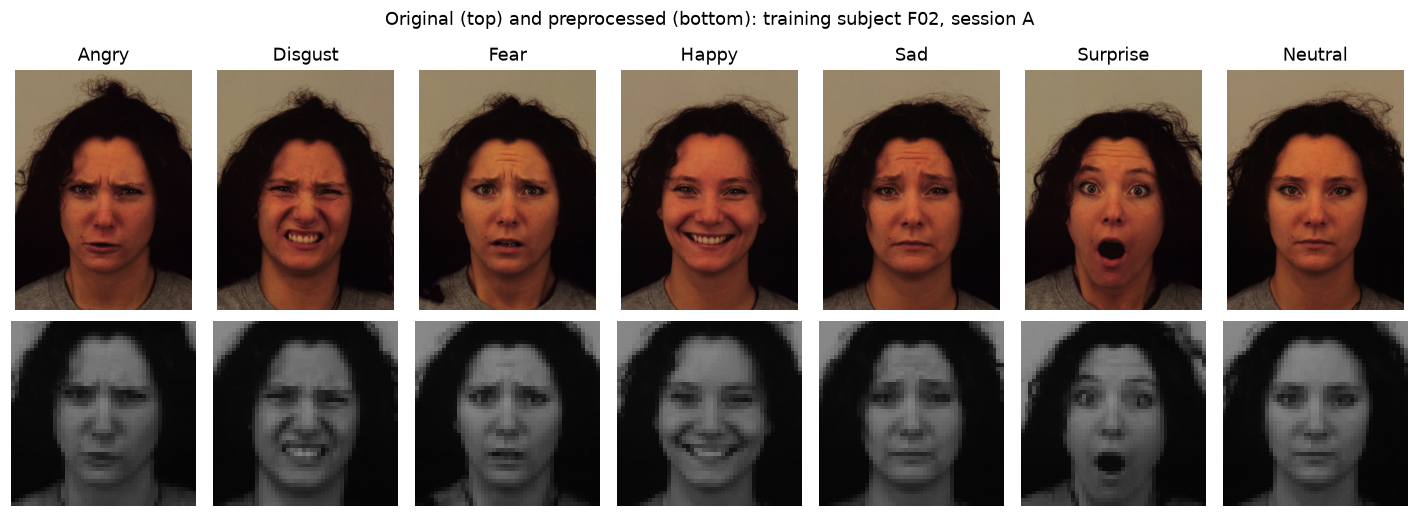

In [12]:
t2_preprocess_signature = {
    'files': [(row.path, (T2_ROOT / row.path).stat().st_size,
               (T2_ROOT / row.path).stat().st_mtime_ns)
              for row in t2_frontal.itertuples()],
    'preprocessing_sha256': hashlib.sha256((T2_ROOT / 'src/preprocess.py').read_bytes()).hexdigest(),
    'detector_sha256': hashlib.sha256((T2_ROOT / 'faceAndLandmarkModels/haarcascade_frontalface_default.xml').read_bytes()).hexdigest(),
    'opencv': cv2.__version__, 'output_size': [48, 48], 'margin': 0.20,
}
t2_cache_key = hashlib.sha256(json.dumps(t2_preprocess_signature, sort_keys=True).encode()).hexdigest()[:16]
t2_cache_file = T2_CACHE / f'preprocessed_{t2_cache_key}.pkl'
if t2_cache_file.exists():
    t2_preprocessed = joblib.load(t2_cache_file)
    print('Loaded preprocessing cache:', t2_cache_file.name)
else:
    start = perf_counter()
    t2_success, t2_images_list, t2_failures_list = [], [], []
    for number, row in enumerate(t2_frontal.to_dict('records'), start=1):
        try:
            image = preprocess_kdef_image(T2_ROOT / row['path'], output_size=(48, 48), margin=0.20)
            assert image.shape == (48, 48) and image.dtype == np.float32
            assert np.isfinite(image).all() and 0 <= image.min() <= image.max() <= 1
            t2_success.append(row)
            t2_images_list.append(image)
        except (ValueError, cv2.error) as error:
            t2_failures_list.append({**row, 'error': str(error)})
        if number % 100 == 0:
            print(f'Preprocessed {number}/{len(t2_frontal)} images', flush=True)
    t2_preprocessed = {'images': np.stack(t2_images_list),
                       'manifest': pd.DataFrame(t2_success),
                       'failures': pd.DataFrame(t2_failures_list, columns=[*t2_frontal.columns, 'error'])}
    joblib.dump(t2_preprocessed, t2_cache_file, compress=3)
    print(f'Preprocessing elapsed: {perf_counter()-start:.1f}s')
t2_images = t2_preprocessed['images']
t2_manifest = t2_preprocessed['manifest'].reset_index(drop=True)
t2_failures = t2_preprocessed['failures']
t2_manifest.to_csv(T2_OUT / 'processed_manifest.csv', index=False)
t2_failures.to_csv(T2_OUT / 'preprocessing_failures.csv', index=False)
print('Failures:', len(t2_failures))
if len(t2_failures):
    display(t2_failures)
display(t2_manifest.groupby('split').agg(images=('path', 'size'), subjects=('subject', 'nunique')))
assert set(t2_manifest.loc[t2_manifest.split == 'train', 'subject']).isdisjoint(
    set(t2_manifest.loc[t2_manifest.split == 'test', 'subject']))

# Inspect one training identity/session; no test-based preprocessing adjustments.
t2_example_subject = sorted(t2_train_subjects)[0]
t2_examples = t2_manifest.loc[(t2_manifest.subject == t2_example_subject) &
                               (t2_manifest.session == 'A')].sort_values('label')
fig, axes = plt.subplots(2, 7, figsize=(13, 5))
for ax in axes.flat:
    ax.axis('off')
for column, (index, row) in enumerate(t2_examples.iterrows()):
    original = cv2.cvtColor(cv2.imread(str(T2_ROOT / row.path)), cv2.COLOR_BGR2RGB)
    axes[0, column].imshow(original)
    axes[0, column].set_title(T2_NAMES[row.label])
    axes[1, column].imshow(t2_images[index], cmap='gray', vmin=0, vmax=1)
fig.suptitle(f'Original (top) and preprocessed (bottom): training subject {t2_example_subject}, session A')
plt.tight_layout()
fig.savefig(T2_OUT / 'preprocessing_examples.png', dpi=160, bbox_inches='tight')
plt.show()

### 2.4 Extract HOG features
We use the same HOG settings as Task 1. The preprocessed KDEF images are already
in [0,1], so they do not need another division by 255. Classifier settings are
copied from Task 1, but all models and scalers are fitted afresh on KDEF.

In [13]:
t2_hog_features = np.stack([hog(image, **T2_HOG) for image in t2_images]).astype(np.float32)
assert t2_hog_features.shape == (len(t2_manifest), 900)
assert np.isfinite(t2_hog_features).all()
t2_train_mask = t2_manifest.split.eq('train').to_numpy()
t2_test_mask = t2_manifest.split.eq('test').to_numpy()
t2_X_train, t2_X_test = t2_hog_features[t2_train_mask], t2_hog_features[t2_test_mask]
t2_y_train = t2_manifest.loc[t2_train_mask, 'label'].to_numpy()
t2_y_test = t2_manifest.loc[t2_test_mask, 'label'].to_numpy()
assert set(t2_y_train) == set(T2_LABELS) and set(t2_y_test) == set(T2_LABELS)
t2_estimators = {name: clone(bundle['classifier']) for name, bundle in t2_fer_bundles.items()}
print('Training HOG shape:', t2_X_train.shape)
print('Test HOG shape:', t2_X_test.shape)

Training HOG shape: (784, 900)
Test HOG shape: (196, 900)


### 2.5 Train and evaluate the three classifiers
All models use the same subject-independent training and test sets. We report
accuracy, balanced accuracy, macro-F1, and confusion matrices, then identify the
highest-scoring configuration for Task 3.

Best Task 2 configuration: HOG + Random Forest


,classifier,accuracy,balanced_accuracy,macro_f1,fit_seconds,selected_for_task3
0,Logistic Regression,0.5612,0.5612,0.5722,0.0482,False
1,Linear SVM,0.4949,0.4949,0.5030,0.5013,False
2,Random Forest,0.6173,0.6173,0.6014,0.4218,True


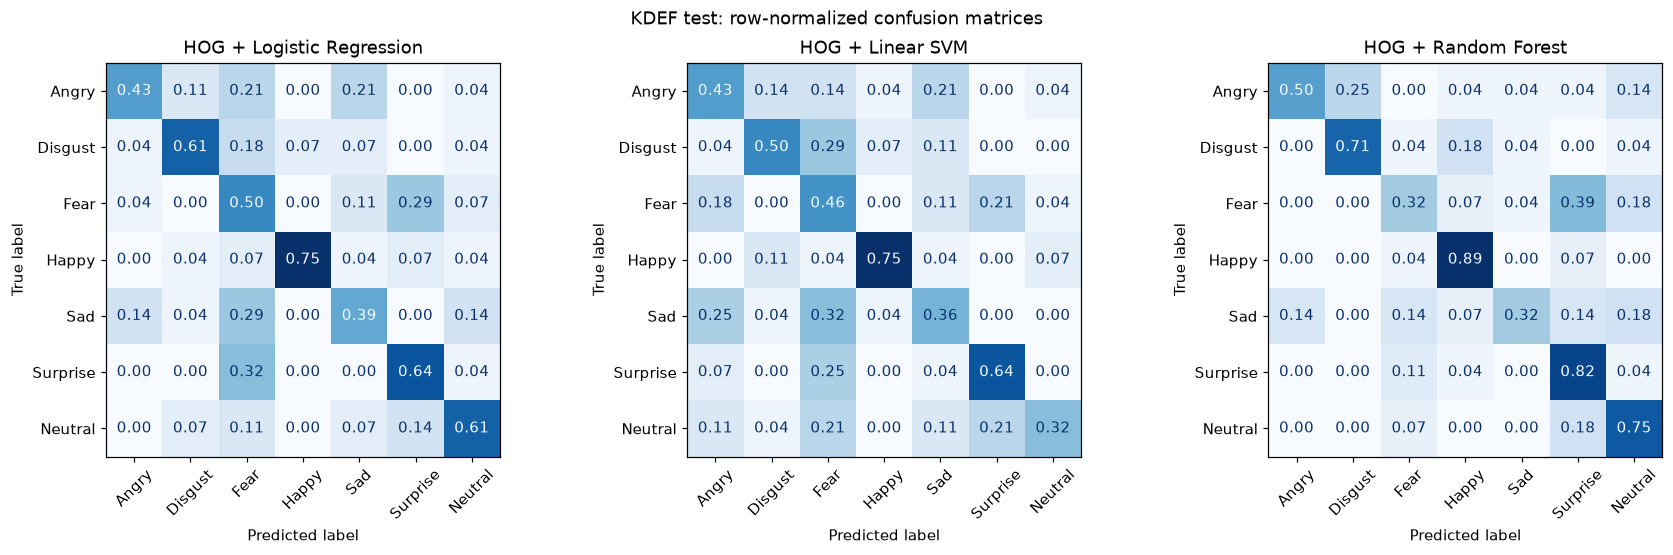

,classifier,emotion,precision,recall,f1-score,support
14,Random Forest,Angry,0.7778,0.5000,0.6087,28.0
15,Random Forest,Disgust,0.7407,0.7143,0.7273,28.0
16,Random Forest,Fear,0.4500,0.3214,0.3750,28.0
17,Random Forest,Happy,0.6944,0.8929,0.7812,28.0
18,Random Forest,Sad,0.7500,0.3214,0.4500,28.0
19,Random Forest,Surprise,0.5000,0.8214,0.6216,28.0
20,Random Forest,Neutral,0.5676,0.7500,0.6462,28.0


In [14]:
def t2_metrics(actual, predicted):
    return {'accuracy': accuracy_score(actual, predicted),
            'balanced_accuracy': balanced_accuracy_score(actual, predicted),
            'macro_f1': f1_score(actual, predicted, labels=T2_LABELS, average='macro', zero_division=0)}

t2_models, t2_fit_seconds = {}, {}
for name, estimator in t2_estimators.items():
    start = perf_counter()
    t2_models[name] = clone(estimator).fit(t2_X_train, t2_y_train)
    t2_fit_seconds[name] = perf_counter() - start

t2_predictions, t2_result_rows, t2_class_rows = {}, [], []
for name, model in t2_models.items():
    predicted = model.predict(t2_X_test)
    t2_predictions[name] = predicted
    t2_result_rows.append({'classifier': name, **t2_metrics(t2_y_test, predicted),
                          'fit_seconds': t2_fit_seconds[name]})
    slug = name.lower().replace(' ', '_')
    report = classification_report(t2_y_test, predicted, labels=T2_LABELS,
                                  target_names=T2_NAMES, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(T2_OUT / f'{slug}_classification_report.csv')
    for emotion in T2_NAMES:
        t2_class_rows.append({'classifier': name, 'emotion': emotion, **report[emotion]})
    prediction_table = t2_manifest.loc[t2_test_mask].reset_index(drop=True).copy()
    prediction_table['predicted'] = predicted
    prediction_table.to_csv(T2_OUT / f'{slug}_test_predictions.csv', index=False)
    np.savetxt(T2_OUT / f'{slug}_confusion_counts.csv',
               confusion_matrix(t2_y_test, predicted, labels=T2_LABELS), delimiter=',', fmt='%d')
t2_results = pd.DataFrame(t2_result_rows)
t2_selected_classifier = t2_results.sort_values('macro_f1', ascending=False).iloc[0]['classifier']
t2_results['selected_for_task3'] = t2_results.classifier.eq(t2_selected_classifier)
t2_selection = {'feature': 'hog', 'selected_classifier': t2_selected_classifier,
    'selection_method': 'Highest Task 2 test macro-F1', 'test_used_for_selection': True,
    'hog_settings': T2_HOG, 'training_subjects': sorted(t2_train_subjects),
    'test_subjects': sorted(t2_test_subjects), 'seed': T2_SEED,
    'preprocessing_cache_key': t2_cache_key}
(T2_OUT / 'frozen_selection.json').write_text(json.dumps(t2_selection, indent=2), encoding='utf-8')
print('Best Task 2 configuration:', 'HOG +', t2_selected_classifier)

t2_class_results = pd.DataFrame(t2_class_rows)
t2_results.to_csv(T2_OUT / 'test_results.csv', index=False)
t2_class_results.to_csv(T2_OUT / 'per_class_test_results.csv', index=False)
display(t2_results.round(4))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, predicted) in zip(axes, t2_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(t2_y_test, predicted, labels=T2_LABELS,
        display_labels=T2_NAMES, normalize='true', values_format='.2f', cmap='Blues',
        colorbar=False, xticks_rotation=45, ax=ax)
    ax.set_title(f'HOG + {name}')
fig.suptitle('KDEF test: row-normalized confusion matrices')
plt.tight_layout()
fig.savefig(T2_OUT / 'test_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()
display(t2_class_results.loc[t2_class_results.classifier == t2_selected_classifier].round(4))

### 2.6 Compare FER2013 and KDEF without conflating this with transfer
Compare the **three HOG models** across datasets; using a landmark forest on FER
and a HOG forest on KDEF would also change the representation. Each model here
was trained and tested within its own dataset. These results measure differences
in within-dataset difficulty, not cross-dataset generalization. Direct transfer
requires applying a source-trained model to the other dataset (Task 3).

,classifier,accuracy_fer,balanced_accuracy_fer,macro_f1_fer,accuracy_kdef,balanced_accuracy_kdef,macro_f1_kdef,accuracy_difference,balanced_accuracy_difference,macro_f1_difference,fer_macro_f1_rank,kdef_macro_f1_rank
0,Logistic Regression,0.4327,0.4040,0.3973,0.5612,0.5612,0.5722,0.1285,0.1572,0.1750,1,2
1,Linear SVM,0.4369,0.3727,0.3726,0.4949,0.4949,0.5030,0.0580,0.1222,0.1303,3,3
2,Random Forest,0.4558,0.3821,0.3971,0.6173,0.6173,0.6014,0.1615,0.2353,0.2044,2,1


,classifier,emotion,fer_f1,kdef_f1
0,Logistic Regression,Angry,0.2941,0.5217
1,Logistic Regression,Disgust,0.3761,0.6538
2,Logistic Regression,Fear,0.2530,0.3733
3,Logistic Regression,Happy,0.6406,0.8235
4,Logistic Regression,Sad,0.2929,0.4151
5,Logistic Regression,Surprise,0.5073,0.6000
6,Logistic Regression,Neutral,0.4169,0.6182
7,Linear SVM,Angry,0.2794,0.4138
8,Linear SVM,Disgust,0.2571,0.5490
9,Linear SVM,Fear,0.2055,0.3421


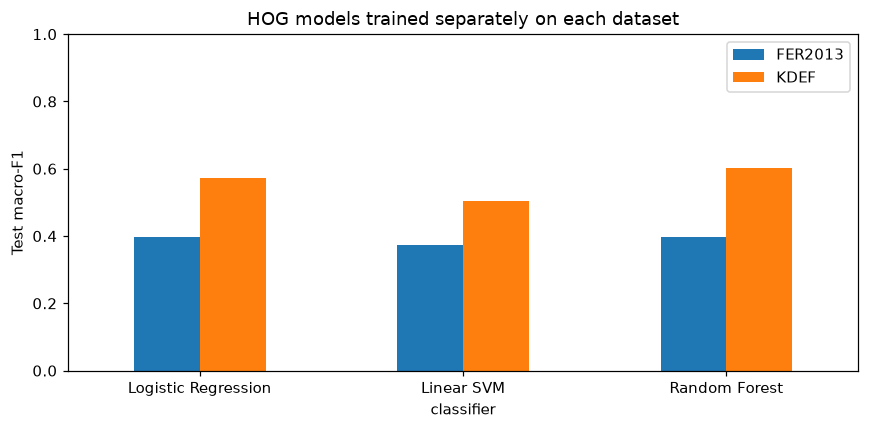

In [15]:
t2_fer_results = pd.read_csv(T2_ROOT / 'results/task1/test_results.csv')
t2_fer_hog = t2_fer_results.loc[t2_fer_results.feature == 'hog',
                               ['classifier', 'accuracy', 'balanced_accuracy', 'macro_f1']]
t2_comparison = t2_fer_hog.merge(t2_results[['classifier', 'accuracy', 'balanced_accuracy', 'macro_f1']],
                                 on='classifier', suffixes=('_fer', '_kdef'), validate='one_to_one')
for metric in ['accuracy', 'balanced_accuracy', 'macro_f1']:
    t2_comparison[f'{metric}_difference'] = t2_comparison[f'{metric}_kdef'] - t2_comparison[f'{metric}_fer']
t2_comparison['fer_macro_f1_rank'] = t2_comparison.macro_f1_fer.rank(ascending=False, method='min').astype(int)
t2_comparison['kdef_macro_f1_rank'] = t2_comparison.macro_f1_kdef.rank(ascending=False, method='min').astype(int)
t2_comparison.to_csv(T2_OUT / 'fer_kdef_comparison.csv', index=False)
display(t2_comparison.round(4))

t2_fer_class_rows = []
for name in t2_models:
    slug = name.lower().replace(' ', '_')
    fer_predictions = pd.read_csv(T2_ROOT / f'results/task1/test_hog_{slug}_predictions.csv')
    report = classification_report(fer_predictions.actual, fer_predictions.predicted,
        labels=T2_LABELS, target_names=T2_NAMES, output_dict=True, zero_division=0)
    for emotion in T2_NAMES:
        t2_fer_class_rows.append({'classifier': name, 'emotion': emotion,
                                 'fer_f1': report[emotion]['f1-score']})
t2_emotion_comparison = pd.DataFrame(t2_fer_class_rows).merge(
    t2_class_results[['classifier', 'emotion', 'f1-score']].rename(columns={'f1-score': 'kdef_f1'}),
    on=['classifier', 'emotion'], validate='one_to_one')
t2_emotion_comparison.to_csv(T2_OUT / 'fer_kdef_per_emotion_comparison.csv', index=False)
display(t2_emotion_comparison.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
t2_comparison.set_index('classifier')[['macro_f1_fer', 'macro_f1_kdef']].plot.bar(ax=ax)
ax.set(ylabel='Test macro-F1', title='HOG models trained separately on each dataset', ylim=(0, 1))
ax.tick_params(axis='x', rotation=0)
ax.legend(['FER2013', 'KDEF'])
plt.tight_layout()
fig.savefig(T2_OUT / 'fer_kdef_macro_f1.png', dpi=160, bbox_inches='tight')
plt.show()

### 2.7 Save KDEF models and preprocessing metadata
Bundles preserve the same classifier/scaler convention as Task 1, but their learned
parameters come exclusively from KDEF training subjects. HOG expects float images
in [0,1] here; FER uint8 pixels must be converted once when using these models later.
The preprocessed image cache and source data remain under the ignored `data/` folder.

In [16]:
for name, model in t2_models.items():
    slug = name.lower().replace(' ', '_')
    bundle = {'classifier': model, 'feature_type': 'hog', 'hog_settings': T2_HOG,
        'emotion_names': T2_NAMES, 'image_shape': (48, 48),
        'hog_input_dtype': 'float32', 'hog_input_range': [0, 1],
        'kdef_preprocessing': {'function': 'src.preprocess.preprocess_kdef_image',
                               'output_size': (48, 48), 'margin': 0.20},
        'training_subjects': sorted(t2_train_subjects),
        'test_subjects': sorted(t2_test_subjects),
        'selected_for_task3': name == t2_selected_classifier,
        'preprocessing_cache_key': t2_cache_key, 'seed': T2_SEED}
    joblib.dump(bundle, T2_MODELS / f'hog_{slug}.pkl', compress=3)
t2_versions = {name: importlib.metadata.version(name) for name in
    ['numpy', 'pandas', 'scikit-learn', 'scikit-image', 'opencv-python', 'joblib']}
(T2_OUT / 'versions.json').write_text(json.dumps(t2_versions, indent=2), encoding='utf-8')
print('Models:', T2_MODELS.relative_to(T2_ROOT))
print('Tables and figures:', T2_OUT.relative_to(T2_ROOT))

Models: models/task2
Tables and figures: results/task2


### 2.8 Conclusions
- All 980 frontal images were processed successfully. The supplied split keeps 56 training and 14 test identities separate, including both sessions of each person.
- HOG + Random Forest achieved the highest test accuracy (60.20%) and macro-F1 (0.5887), so we use it in Task 3. LR obtained macro-F1 0.5722 and linear SVM 0.5030.
- All three HOG models scored higher on KDEF than FER2013. The macro-F1 ranking changed from LR > RF > SVM to RF > LR > SVM.
- For RF, Happy had the highest F1 (0.7937); Fear (0.3600) and Sad (0.4286) were more difficult.
- These are separately trained, within-dataset models. They do not yet measure transfer. Each KDEF test class contains only 28 images from 14 identities.

## 3. Cross-Dataset Generalization (20%)


### 3.1 Setup
We take HOG + Random Forest, the best-performing Task 2 configuration, and retrain
it on all 980 frontal KDEF images. We then evaluate it directly on FER2013 PrivateTest.
The former KDEF test images are now source-training images; no FER images are used
to fit this model.

In [17]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from skimage.feature import hog
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from src.preprocess import preprocess_kdef_image

T3_ROOT = Path.cwd()
T3_OUT, T3_MODELS = T3_ROOT / 'results/task3', T3_ROOT / 'models/task3'
for folder in [T3_OUT, T3_MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
T3_NAMES = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
T3_LABELS = np.arange(7)
t3_selection = json.loads((T3_ROOT / 'results/task2/frozen_selection.json').read_text())
assert t3_selection['feature'] == 'hog' and t3_selection['selected_classifier'] == 'Random Forest'
t3_source_bundle = joblib.load(T3_ROOT / 'models/task2/hog_random_forest.pkl')
T3_HOG = t3_source_bundle['hog_settings']

### 3.2 Preprocess KDEF and load FER2013
We apply the supplied KDEF face crop, grayscale conversion, resizing, and
normalization. FER images are already 48 x 48 grayscale; their pixels are divided
by 255 to use the same [0,1] range. The emotion codes are the same in both datasets.

In [18]:
t3_manifest = pd.read_csv(T3_ROOT / 'results/task2/frontal_manifest.csv')
assert len(t3_manifest) == 980 and set(t3_manifest.pose) == {'S'}
assert t3_manifest.subject.nunique() == 70 and not t3_manifest.path.duplicated().any()
t3_mapping = {'AN': 0, 'DI': 1, 'AF': 2, 'HA': 3, 'SA': 4, 'SU': 5, 'NE': 6}
assert np.array_equal(t3_manifest.emotion_code.map(t3_mapping), t3_manifest.label)
t3_kdef_images = np.stack([preprocess_kdef_image(T3_ROOT / path) for path in t3_manifest.path])
t3_kdef_y = t3_manifest.label.to_numpy(dtype=int)
assert t3_kdef_images.shape == (980, 48, 48)
assert 0 <= t3_kdef_images.min() <= t3_kdef_images.max() <= 1

t3_csv = next(path for path in [T3_ROOT / 'data/fer2013.csv', T3_ROOT / 'data/fer/fer2013.csv'] if path.exists())
t3_fer_df = pd.read_csv(t3_csv)
t3_fer_test = t3_fer_df.loc[t3_fer_df.Usage == 'PrivateTest'].reset_index(drop=True)
t3_pixels = np.stack([np.fromstring(row, sep=' ', dtype=np.int32) for row in t3_fer_test.pixels])
assert t3_pixels.shape == (3589, 2304) and 0 <= t3_pixels.min() <= t3_pixels.max() <= 255
t3_fer_images = t3_pixels.reshape(-1, 48, 48).astype(np.float32) / 255.0
t3_fer_y = t3_fer_test.emotion.to_numpy(dtype=int)
print('KDEF source images:', len(t3_kdef_images))
print('FER test images:', len(t3_fer_images))

KDEF source images: 980
FER test images: 3589


### 3.3 Extract HOG and retrain Random Forest
We keep the HOG and RF settings from Task 2. Only the model fit is repeated,
using all frontal KDEF images. Nothing is fitted or tuned on FER2013.

In [19]:
t3_X_kdef = np.stack([hog(image, **T3_HOG) for image in t3_kdef_images]).astype(np.float32)
t3_X_fer = np.stack([hog(image, **T3_HOG) for image in t3_fer_images]).astype(np.float32)
assert t3_X_kdef.shape == (980, 900) and t3_X_fer.shape == (3589, 900)
assert np.isfinite(t3_X_kdef).all() and np.isfinite(t3_X_fer).all()
t3_model = clone(t3_source_bundle['classifier'])
t3_model.fit(t3_X_kdef, t3_kdef_y)
print(t3_model)

RandomForestClassifier(criterion='entropy', max_depth=11, n_estimators=300,
                       n_jobs=-1, random_state=42)


### 3.4 Evaluate directly on FER2013
We report accuracy, balanced accuracy, macro-F1, per-emotion scores, and a
confusion matrix. The full interpretation belongs in the report.

,direction,feature,classifier,source_images,target_images,accuracy,balanced_accuracy,macro_f1
0,KDEF -> FER,HOG,Random Forest,980,3589,0.2179,0.2139,0.1706


,precision,recall,f1-score,support
Angry,0.2358,0.0509,0.0838,491.0000
Disgust,0.0345,0.1455,0.0557,55.0000
Fear,0.1488,0.1894,0.1667,528.0000
Happy,0.4030,0.3026,0.3457,879.0000
Sad,0.1994,0.2391,0.2175,594.0000
Surprise,0.1954,0.5505,0.2884,416.0000
Neutral,0.3429,0.0192,0.0363,626.0000
accuracy,0.2179,0.2179,0.2179,0.2179
macro avg,0.2228,0.2139,0.1706,3589.0000
weighted avg,0.2689,0.2179,0.1972,3589.0000


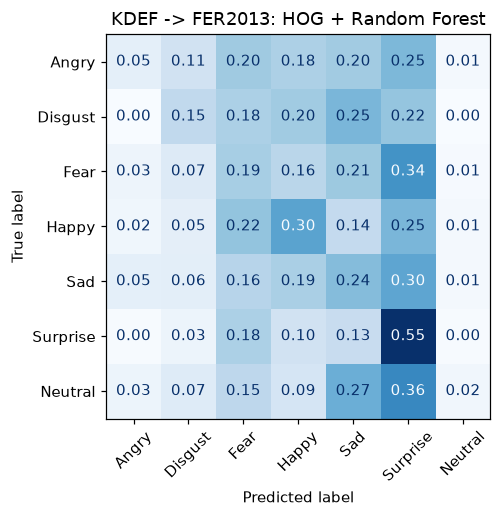

In [20]:
t3_pred = t3_model.predict(t3_X_fer)
t3_metrics = {'accuracy': accuracy_score(t3_fer_y, t3_pred),
    'balanced_accuracy': balanced_accuracy_score(t3_fer_y, t3_pred),
    'macro_f1': f1_score(t3_fer_y, t3_pred, labels=T3_LABELS, average='macro', zero_division=0)}
t3_results = pd.DataFrame([{'direction': 'KDEF -> FER', 'feature': 'HOG',
    'classifier': 'Random Forest', 'source_images': 980, 'target_images': 3589, **t3_metrics}])
display(t3_results.round(4))
t3_report = pd.DataFrame(classification_report(t3_fer_y, t3_pred, labels=T3_LABELS,
    target_names=T3_NAMES, output_dict=True, zero_division=0)).T
display(t3_report.round(4))
ConfusionMatrixDisplay.from_predictions(t3_fer_y, t3_pred, labels=T3_LABELS,
    display_labels=T3_NAMES, normalize='true', values_format='.2f', cmap='Blues',
    xticks_rotation=45, colorbar=False)
plt.title('KDEF -> FER2013: HOG + Random Forest')
plt.tight_layout()
plt.savefig(T3_OUT / 'kdef_to_fer_confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

### 3.5 Save results and model
The refitted model is saved separately from Task 2 to preserve its original
subject-independent evaluation.

In [21]:
t3_results.to_csv(T3_OUT / 'transfer_results.csv', index=False)
t3_report.to_csv(T3_OUT / 'classification_report.csv')
pd.DataFrame({'fer_test_row': np.arange(len(t3_pred)), 'actual': t3_fer_y,
              'predicted': t3_pred}).to_csv(T3_OUT / 'predictions.csv', index=False)
np.savetxt(T3_OUT / 'confusion_counts.csv', confusion_matrix(t3_fer_y, t3_pred,
    labels=T3_LABELS), delimiter=',', fmt='%d')
t3_manifest.to_csv(T3_OUT / 'kdef_source_manifest.csv', index=False)
t3_bundle = {'classifier': t3_model, 'feature_type': 'hog', 'hog_settings': T3_HOG,
    'emotion_names': T3_NAMES, 'image_shape': (48, 48), 'hog_input_range': [0, 1],
    'source_dataset': 'KDEF', 'source_images': 980,
    'source_subjects': sorted(t3_manifest.subject.unique()),
    'preprocessing': 'src.preprocess.preprocess_kdef_image',
    'selection_method': 'Highest Task 2 test macro-F1'}
joblib.dump(t3_bundle, T3_MODELS / 'kdef_all_hog_random_forest.pkl', compress=3)
print('Saved Task 3 model and results.')

Saved Task 3 model and results.


### 3.6 Conclusions
- The KDEF-trained HOG + RF model obtained 21.65% accuracy, 20.69% balanced accuracy, and 0.1678 macro-F1 on FER2013.
- Performance is lower than the FER-trained HOG + RF reference (45.33% accuracy; 0.3933 macro-F1), showing poor transfer for this configuration.
- Happy and Surprise have the highest transfer F1 scores (0.3461 and 0.2789); Disgust and Neutral are particularly difficult.
- Both datasets use the same image format and HOG settings, but cropping, appearance, and class distributions still differ. We discuss these limitations in the report.

## 4. Explainable Fuzzy Classifier (10%)

### 4.1 Setup and landmark extraction
This section runs independently of Tasks 1–3 but reuses the Task 2 frontal manifest
(`results/task2/frontal_manifest.csv`): 980 frontal images, both sessions, and the supplied
56/14 identity split. Landmarks come from dlib's 68-point shape predictor. We run it on the
**full-resolution** KDEF image, not the 48×48 FER-format crop, because the features measure
small distances such as eye opening, and at 48×48 these would cover only a pixel or two.
Face boxes come from dlib's HOG frontal detector, which the shape predictor was trained with.
The supplied Haar cascade, with the Task 2 settings, is used only as a fallback. Landmarks are cached
with source-file metadata and the predictor checksum, like the Task 2 preprocessing cache.

The fuzzy model needs pyFUME, which pins numpy 1.24.4, pandas 1.5.3, and scipy 1.10.1. These
conflict with this environment, so feature extraction (4.1–4.2) runs here. The fuzzy
classifier is trained in the `emotion-fuzzy` environment (`environment-fuzzy.yml`), which
reads `results/task4/geometric_features.csv`.

In [22]:
from pathlib import Path
from time import perf_counter
import hashlib
import importlib.metadata
import json

import cv2
import dlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

T4_ROOT = Path.cwd()
assert (T4_ROOT / 'emotion_detection_group11.ipynb').exists(), 'Run from the repository folder.'
T4_OUT = T4_ROOT / 'results' / 'task4'
T4_CACHE = T4_ROOT / 'data' / 'feature_cache' / 'task4'
for folder in [T4_OUT, T4_CACHE]:
    folder.mkdir(parents=True, exist_ok=True)
T4_NAMES = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
T4_LABELS = np.arange(7)
T4_PREDICTOR_PATH = T4_ROOT / 'faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat'
T4_HAAR_PATH = T4_ROOT / 'faceAndLandmarkModels/haarcascade_frontalface_default.xml'
t4_detector = dlib.get_frontal_face_detector()
t4_predictor = dlib.shape_predictor(str(T4_PREDICTOR_PATH))
t4_haar = cv2.CascadeClassifier(str(T4_HAAR_PATH))
assert not t4_haar.empty(), 'The supplied Haar cascade did not load.'

# Reuse the Task 2 frontal inventory and the supplied 56/14 identity split unchanged.
t4_frontal = pd.read_csv(T4_ROOT / 'results/task2/frontal_manifest.csv')
# The manifest may be written on Windows; forward slashes resolve on every OS.
t4_frontal['path'] = t4_frontal.path.str.replace('\\', '/', regex=False)
assert len(t4_frontal) == 980 and set(t4_frontal.pose) == {'S'}
assert t4_frontal.groupby('subject')['split'].nunique().max() == 1
display(t4_frontal.groupby('split').agg(images=('path', 'size'), subjects=('subject', 'nunique')))
print('dlib:', dlib.__version__, '| OpenCV:', cv2.__version__)

,images,subjects
split,,
test,196,14
train,784,56


dlib: 20.0.1 | OpenCV: 4.11.0


Loaded landmark cache: landmarks_a6524ca26901eeed.pkl
Failures: 0 | detector used: {'dlib': 980}


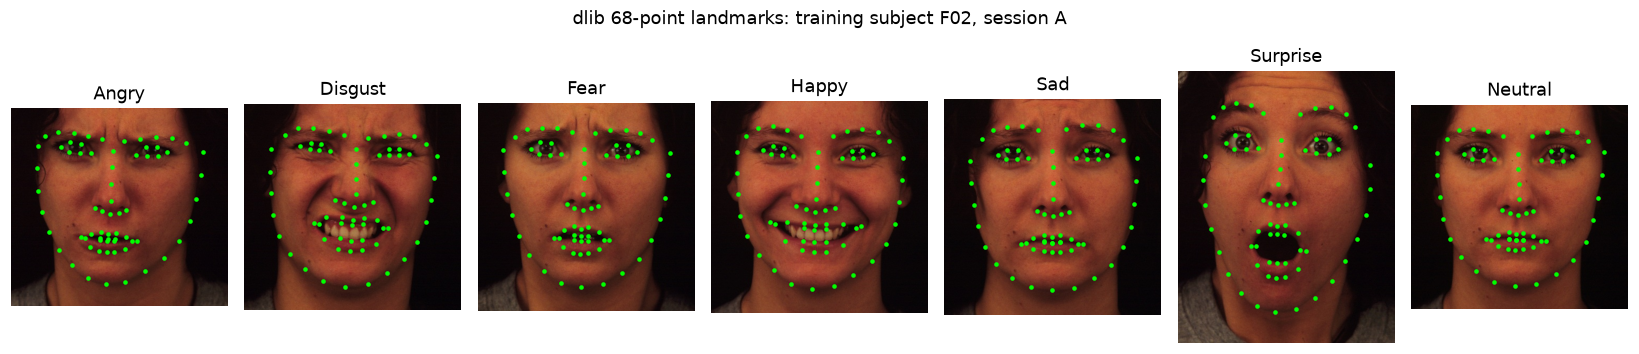

In [23]:
def t4_detect_landmarks(image_path):
    """Return (68x2 float landmarks, detector name) from a full-resolution KDEF image."""
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f'Could not read {image_path}')
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    faces = t4_detector(gray, 0)
    if len(faces):
        box, source = max(faces, key=lambda r: r.width() * r.height()), 'dlib'
    else:
        # Fall back to the Task 2 Haar settings when dlib's HOG detector misses the face.
        haar = t4_haar.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(50, 50))
        if len(haar) == 0:
            raise ValueError(f'No face detected in {image_path}')
        x, y, w, h = (int(v) for v in max(haar, key=lambda f: f[2] * f[3]))
        box, source = dlib.rectangle(x, y, x + w, y + h), 'haar'
    shape = t4_predictor(gray, box)
    points = np.array([[p.x, p.y] for p in shape.parts()], dtype=np.float64)
    return points, source

t4_landmark_signature = {
    'files': [(row.path, (T4_ROOT / row.path).stat().st_size,
               (T4_ROOT / row.path).stat().st_mtime_ns)
              for row in t4_frontal.itertuples()],
    'predictor_sha256': hashlib.sha256(T4_PREDICTOR_PATH.read_bytes()).hexdigest(),
    'detector': 'dlib HOG (upsample 0), Haar fallback',
    'dlib': dlib.__version__, 'opencv': cv2.__version__,
}
t4_cache_key = hashlib.sha256(json.dumps(t4_landmark_signature, sort_keys=True).encode()).hexdigest()[:16]
t4_cache_file = T4_CACHE / f'landmarks_{t4_cache_key}.pkl'
if t4_cache_file.exists():
    t4_landmark_data = joblib.load(t4_cache_file)
    print('Loaded landmark cache:', t4_cache_file.name)
else:
    start = perf_counter()
    t4_success, t4_points_list, t4_failures_list = [], [], []
    for number, row in enumerate(t4_frontal.to_dict('records'), start=1):
        try:
            points, source = t4_detect_landmarks(T4_ROOT / row['path'])
            t4_success.append({**row, 'detector': source})
            t4_points_list.append(points)
        except ValueError as error:
            t4_failures_list.append({**row, 'error': str(error)})
        if number % 200 == 0:
            print(f'Landmarked {number}/{len(t4_frontal)} images', flush=True)
    t4_landmark_data = {'landmarks': np.stack(t4_points_list),
                        'manifest': pd.DataFrame(t4_success),
                        'failures': pd.DataFrame(t4_failures_list, columns=[*t4_frontal.columns, 'error'])}
    joblib.dump(t4_landmark_data, t4_cache_file, compress=3)
    print(f'Landmark extraction elapsed: {perf_counter()-start:.1f}s')
t4_landmarks = t4_landmark_data['landmarks']
t4_manifest = t4_landmark_data['manifest'].reset_index(drop=True)
t4_failures = t4_landmark_data['failures']
t4_failures.to_csv(T4_OUT / 'landmark_failures.csv', index=False)
print('Failures:', len(t4_failures), '| detector used:', t4_manifest.detector.value_counts().to_dict())
if len(t4_failures):
    display(t4_failures)

# Visual check on one training identity; landmarks are never inspected on test subjects.
t4_example_subject = sorted(t4_manifest.loc[t4_manifest.split == 'train', 'subject'].unique())[0]
t4_examples = t4_manifest.loc[(t4_manifest.subject == t4_example_subject) &
                               (t4_manifest.session == 'A')].sort_values('label')
fig, axes = plt.subplots(1, 7, figsize=(15, 3.4))
for ax, (index, row) in zip(axes, t4_examples.iterrows()):
    points = t4_landmarks[index]
    image = cv2.cvtColor(cv2.imread(str(T4_ROOT / row.path)), cv2.COLOR_BGR2RGB)
    pad = 0.15 * np.ptp(points, axis=0)
    (x1, y1), (x2, y2) = (points.min(0) - pad).astype(int), (points.max(0) + pad).astype(int)
    ax.imshow(image[max(y1, 0):y2, max(x1, 0):x2])
    ax.scatter(points[:, 0] - max(x1, 0), points[:, 1] - max(y1, 0), s=4, c='lime')
    ax.set_title(T4_NAMES[row.label])
    ax.axis('off')
fig.suptitle(f'dlib 68-point landmarks: training subject {t4_example_subject}, session A')
plt.tight_layout()
fig.savefig(T4_OUT / 'landmark_examples.png', dpi=160, bbox_inches='tight')
plt.show()

### 4.2 Handcrafted geometric features
Landmarks are first aligned: the eye midpoint is moved to the origin, the eye line is rotated
to horizontal, and all coordinates are divided by the inter-ocular distance. The features are
then independent of face size and head roll. We use seven features, within the 3–10 that the
assignment allows. Each one corresponds to a visible facial action. The three brow features measure the inner
brow separately from the outer brow, because inner-brow raising (Sad, Fear) and brow
lowering with the brows drawn together (Angry) are what separate the negative emotions:

| Feature | Landmarks (dlib 68) | Expected to separate |
|---|---|---|
| `mouth_open` | inner lips 61–67, 62–66, 63–65 | Surprise, Fear |
| `mouth_width` | corners 48–54 | Happy, Fear |
| `lip_corner_lift` | corners 48/54 vs. lip midline 51/57 | Happy vs. Sad |
| `eye_open` | eye aspect ratio, 36–41 and 42–47 | Surprise, Fear |
| `inner_brow_raise` | inner brows 20–23 vs. upper eyelids 37/38/43/44 | raised: Sad, Fear, Surprise; lowered: Angry, Disgust |
| `brow_slant` | inner brow ends 21/22 vs. outer ends 17/26 | + slanted up: Sad, Fear; − V-shaped frown: Angry |
| `inner_brow_gap` | inner brow ends 21–22 | Angry (brows drawn together) |

Distributions and correlations are inspected on **training identities only**. A pair with
|r| > 0.9 would be redundant and would add rules without adding information.

Saved 980 rows x 7 features to results/task4/geometric_features.csv


,mouth_open,mouth_width,lip_corner_lift,eye_open,inner_brow_raise,brow_slant,inner_brow_gap
emotion,,,,,,,
Angry,0.022,0.804,0.055,0.290,0.101,-0.014,0.269
Disgust,0.116,0.855,0.055,0.227,0.144,0.027,0.325
Fear,0.142,0.832,0.044,0.380,0.223,0.116,0.320
Happy,0.186,1.110,0.169,0.268,0.218,0.073,0.397
Sad,0.012,0.849,0.017,0.300,0.238,0.119,0.318
Surprise,0.206,0.752,0.049,0.420,0.261,0.087,0.408
Neutral,0.008,0.825,0.022,0.338,0.200,0.062,0.362


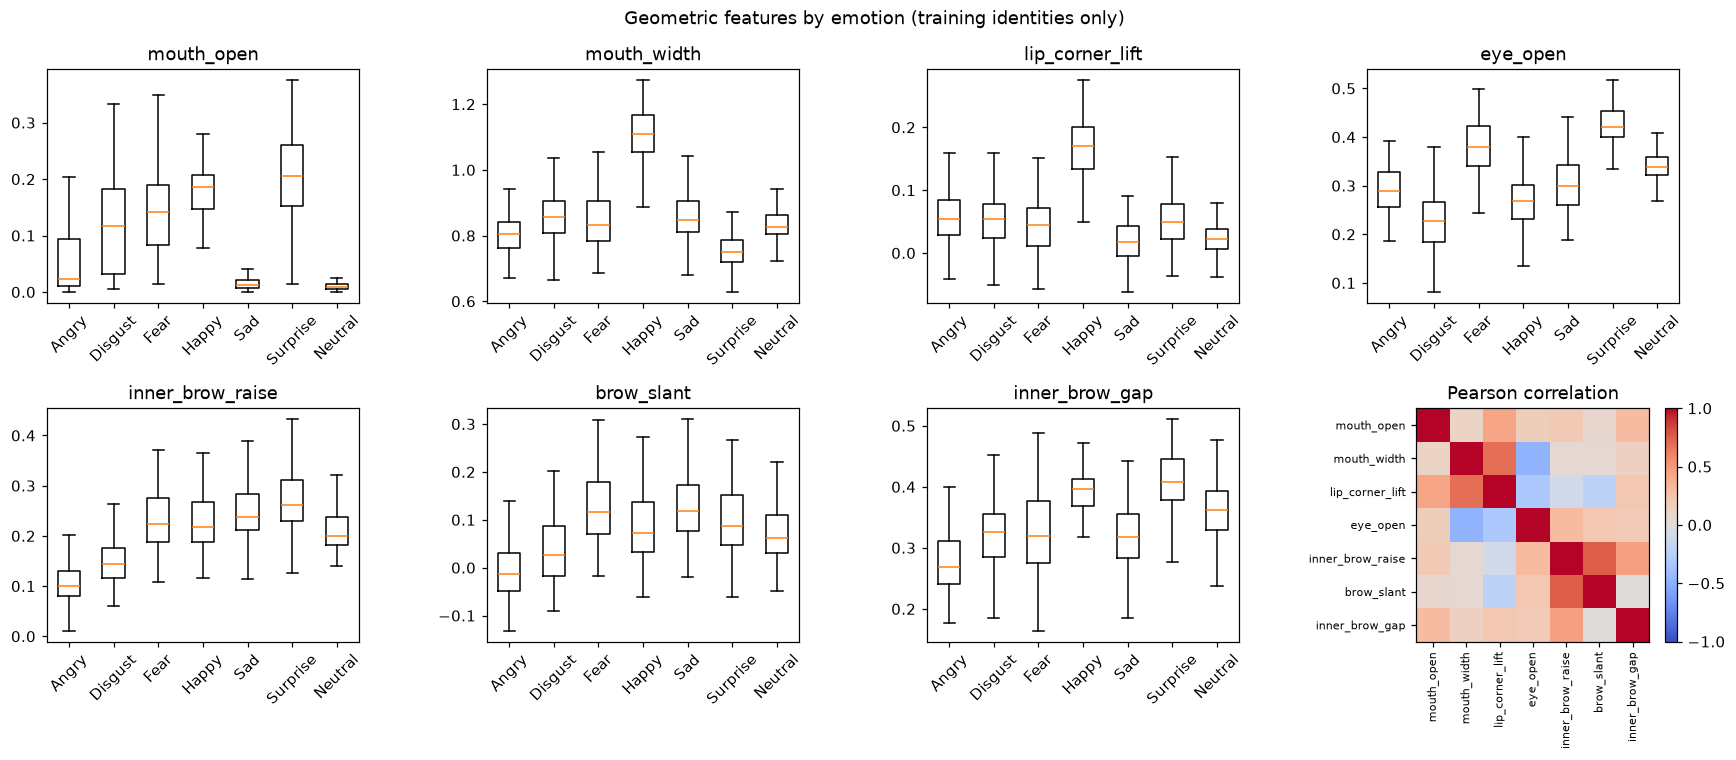

Feature pairs with |r| > 0.9: none


121

In [24]:
def t4_align(points):
    """Translate to the eye midpoint, rotate the eye line horizontal, and scale by inter-ocular distance."""
    left_eye, right_eye = points[36:42].mean(0), points[42:48].mean(0)
    dx, dy = right_eye - left_eye
    iod = np.hypot(dx, dy)
    cos, sin = dx / iod, dy / iod
    rotation = np.array([[cos, sin], [-sin, cos]])
    return (points - (left_eye + right_eye) / 2) @ rotation.T / iod

def t4_geometric_features(points):
    """Seven scale- and roll-invariant measurements in inter-ocular units (image y points down)."""
    p = t4_align(points)
    dist = lambda a, b: np.linalg.norm(p[a] - p[b])
    eye_width = (dist(36, 39) + dist(42, 45)) / 2
    return {
        # Vertical gap between inner lips (Surprise, Fear).
        'mouth_open': np.mean([dist(61, 67), dist(62, 66), dist(63, 65)]),
        # Distance between mouth corners (Happy, Fear).
        'mouth_width': dist(48, 54),
        # Mouth corners above (+) or below (-) the lip midline (Happy vs. Sad).
        'lip_corner_lift': (p[51, 1] + p[57, 1]) / 2 - (p[48, 1] + p[54, 1]) / 2,
        # Eye aspect ratio, averaged over both eyes (Surprise, Fear).
        'eye_open': (dist(37, 41) + dist(38, 40) + dist(43, 47) + dist(44, 46)) / (4 * eye_width),
        # Inner brow height above the upper eyelids (raised in Sad, Fear, Surprise; lowered in Angry).
        'inner_brow_raise': p[[37, 38, 43, 44], 1].mean() - p[20:24, 1].mean(),
        # Inner minus outer brow height: + slanted up (Sad), - V-shaped frown (Angry).
        'brow_slant': p[[17, 26], 1].mean() - p[[21, 22], 1].mean(),
        # Gap between the inner brow ends (drawn together in Angry).
        'inner_brow_gap': dist(21, 22),
    }

T4_FEATURES = list(t4_geometric_features(t4_landmarks[0]))
t4_features = pd.concat([
    t4_manifest[['path', 'session', 'subject', 'emotion_code', 'label', 'split']],
    pd.DataFrame([t4_geometric_features(points) for points in t4_landmarks]),
], axis=1)
t4_features.insert(t4_features.columns.get_loc('label') + 1, 'emotion',
                   [T4_NAMES[label] for label in t4_features.label])
assert np.isfinite(t4_features[T4_FEATURES].to_numpy()).all()
t4_features.to_csv(T4_OUT / 'geometric_features.csv', index=False)
print(f'Saved {len(t4_features)} rows x {len(T4_FEATURES)} features to results/task4/geometric_features.csv')

# Inspect only training identities: per-emotion distributions and redundancy.
t4_train = t4_features.loc[t4_features.split == 'train']
display(t4_train.groupby('emotion')[T4_FEATURES].median().reindex(T4_NAMES).round(3))
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, feature in zip(axes.flat, T4_FEATURES):
    ax.boxplot([t4_train.loc[t4_train.label == label, feature] for label in T4_LABELS],
               showfliers=False)
    ax.set_xticks(T4_LABELS + 1, T4_NAMES, rotation=45)
    ax.set_title(feature)
t4_corr = t4_train[T4_FEATURES].corr()
image = axes.flat[-1].imshow(t4_corr, cmap='coolwarm', vmin=-1, vmax=1)
axes.flat[-1].set_xticks(range(len(T4_FEATURES)), T4_FEATURES, rotation=90, fontsize=7)
axes.flat[-1].set_yticks(range(len(T4_FEATURES)), T4_FEATURES, fontsize=7)
axes.flat[-1].set_title('Pearson correlation')
fig.colorbar(image, ax=axes.flat[-1], fraction=0.046)
fig.suptitle('Geometric features by emotion (training identities only)')
plt.tight_layout()
fig.savefig(T4_OUT / 'feature_distributions.png', dpi=160, bbox_inches='tight')
plt.show()
t4_redundant = [(a, b, round(t4_corr.loc[a, b], 3)) for i, a in enumerate(T4_FEATURES)
                for b in T4_FEATURES[i + 1:] if abs(t4_corr.loc[a, b]) > 0.9]
print('Feature pairs with |r| > 0.9:', t4_redundant or 'none')

t4_versions = {package: importlib.metadata.version(package)
               for package in ['numpy', 'pandas', 'dlib', 'opencv-python', 'matplotlib']}
(T4_OUT / 'versions.json').write_text(json.dumps(t4_versions, indent=2))

## 5. Creative Challenge (25%)

### 5.1. Revisiting FER2013 Best Model
In Section 1.6, we found that Logistic Regression + HOG features was the best model/feature combination with macro-F1 of 0.4 on the validation set (PublicTest). Let us confirm this one more time to set this model and feature combination as our starting point for the comparison of this section.

In [30]:
# Load the trained model
lr_clf = joblib.load('models/task1/hog_logistic_regression.pkl')["classifier"]
validation_predictions = lr_clf.predict(features["hog"]["validation"])
validation_scores = metric_scores(y["validation"], validation_predictions)
validation_scores


{'accuracy': 0.4363332404569518,
 'balanced_accuracy': 0.40210218788158636,
 'macro_f1': 0.4000102589631055}

### 5.2. Class Balancing
As discussed in Section 1.2, there is a class imbalance across the target emotions. We plot the same class distribution in the training set again confirm.

,emotion,training_images
0,Angry,3995
1,Disgust,436
2,Fear,4097
3,Happy,7215
4,Sad,4830
5,Surprise,3171
6,Neutral,4965


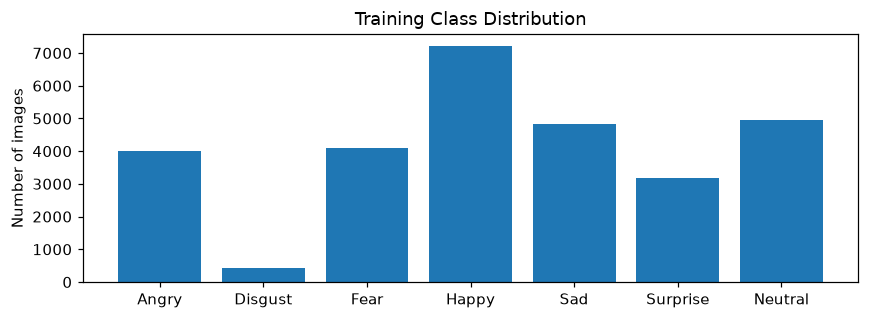

In [32]:
plot_class_distribution(y["train"], "Training Class Distribution")

As can be seen on the bar chart above, the emotion Disgust is severly under represented in the training set. By using macro-f1 as the metric for model selection leads to rare classes like Disgust to be weighted equally as the other models, and since there's a lack of training images for discuss, the model barely predicts them accurately. We attempted this class imbalance issue by setting the ```class_weight``` parameter to "balanced" when training the classifier.

In [36]:
from time import perf_counter

from sklearn.base import clone

# Refit the three Task 1 HOG configurations with and without class weighting, so both
# variants are trained under identical conditions and only class_weight differs.
hog_bundles = {
    'Logistic Regression': 'hog_logistic_regression',
    'Linear SVM': 'hog_linear_svm',
    'Random Forest': 'hog_random_forest',
}
balancing_rows, balancing_predictions = [], {}
for name, file in hog_bundles.items():
    task1_model = joblib.load(f'models/task1/{file}.pkl')['classifier']
    for class_weight in [None, 'balanced']:
        model = clone(task1_model)
        # Pipelines need the step-name prefix; Random Forest takes the parameter directly.
        key = f'{model.steps[-1][0]}__class_weight' if hasattr(model, 'steps') else 'class_weight'
        model.set_params(**{key: class_weight})
        start = perf_counter()
        model.fit(features['hog']['train'], y['train'])
        fit_seconds = perf_counter() - start
        predictions = model.predict(features['hog']['validation'])
        balancing_predictions[name, class_weight or 'none'] = predictions
        balancing_rows.append({
            'classifier': name, 'class_weight': class_weight or 'none',
            **metric_scores(y['validation'], predictions),
            # Disgust (label 1) is the class the weighting affects most.
            'disgust_predicted': int((predictions == 1).sum()),
            'disgust_f1': f1_score(y['validation'], predictions, labels=[1], average=None,
                                   zero_division=0)[0],
            'fit_seconds': fit_seconds,
        })
        print(f'{name} ({class_weight or "none"}): fitted in {fit_seconds:.1f}s', flush=True)

balancing_results = pd.DataFrame(balancing_rows)
print('Disgust images in validation:', int((y['validation'] == 1).sum()))
display(balancing_results.round(4))

Logistic Regression (none): fitted in 4.5s
Logistic Regression (balanced): fitted in 4.0s
Linear SVM (none): fitted in 61.2s
Linear SVM (balanced): fitted in 63.1s
Random Forest (none): fitted in 28.3s
Random Forest (balanced): fitted in 40.2s
Disgust images in validation: 56


,classifier,class_weight,accuracy,balanced_accuracy,macro_f1,disgust_predicted,disgust_f1,fit_seconds
0,Logistic Regression,none,0.4363,0.4021,0.4000,55,0.3423,4.4840
1,Logistic Regression,balanced,0.4132,0.4227,0.3740,253,0.2071,3.9564
2,Linear SVM,none,0.4478,0.3836,0.3880,13,0.2609,61.2020
3,Linear SVM,balanced,0.4269,0.4292,0.3721,257,0.2045,63.0669
4,Random Forest,none,0.4483,0.3734,0.3866,11,0.3284,28.2747
5,Random Forest,balanced,0.4625,0.4363,0.4325,40,0.4792,40.1718


Although the balanced accuracy for the validation set increased from 0.40 to 0.42, the macro-F1 score dropped from 0.40 to 0.37. 

### 5.3. Data Augmentation

We will now see if augmenting our training set will improve the model's performance. The strategy we use is adding a mirrored copy of every training image.

Extracted hog/train_flipped: (28709, 900), 5.5s
Training set: 28709 -> 57418 images


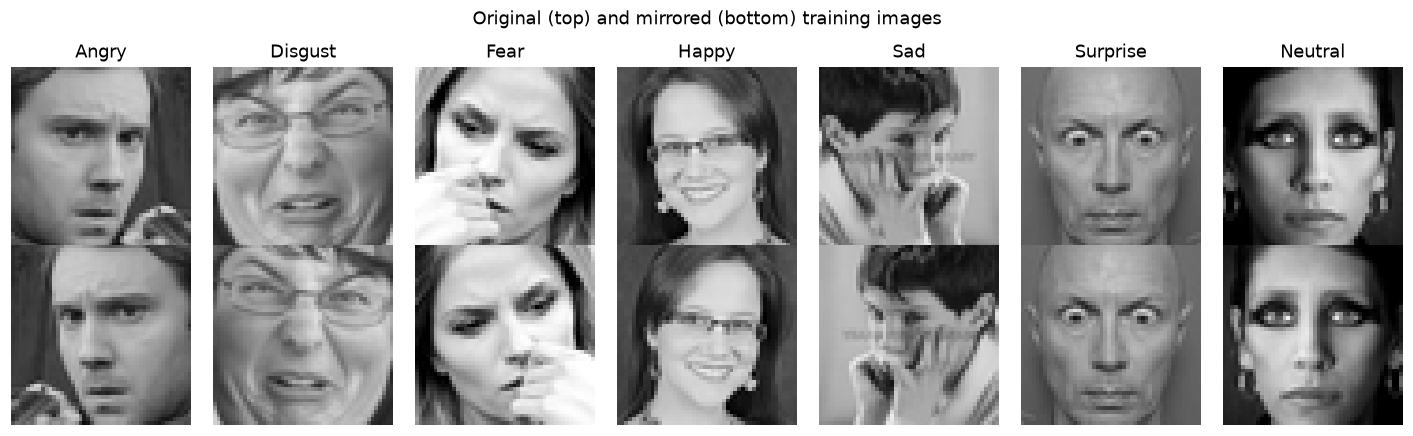

Linear SVM (none): fitted in 126.5s
Logistic Regression (none): fitted in 7.9s
Random Forest (balanced): fitted in 53.3s


,classifier,class_weight,accuracy,balanced_accuracy,macro_f1,disgust_predicted,disgust_f1,fit_seconds,training
0,Linear SVM,none,0.4478,0.3836,0.3880,13,0.2609,61.2020,original
3,Linear SVM,none,0.4458,0.3703,0.3674,6,0.1613,126.5100,original + mirrored
1,Logistic Regression,none,0.4363,0.4021,0.4000,55,0.3423,4.4840,original
4,Logistic Regression,none,0.4464,0.3981,0.4033,33,0.3146,7.8666,original + mirrored
2,Random Forest,balanced,0.4625,0.4363,0.4325,40,0.4792,40.1718,original
5,Random Forest,balanced,0.4475,0.4405,0.4151,70,0.4762,53.2545,original + mirrored


In [37]:
# Mirror every training image left-right. A mirrored face shows the same emotion, so the
# labels are reused unchanged. Only Training is augmented; validation images stay untouched.
flipped_train = np.ascontiguousarray(images['train'][:, :, ::-1])
features['hog']['train_flipped'] = cached_features('hog', 'train_flipped', flipped_train)
X_train_augmented = np.concatenate([features['hog']['train'], features['hog']['train_flipped']])
y_train_augmented = np.concatenate([y['train'], y['train']])
print('Training set:', len(y['train']), '->', len(y_train_augmented), 'images')

fig, axes = plt.subplots(2, 7, figsize=(13, 4))
for label, (top, bottom) in enumerate(zip(axes[0], axes[1])):
    index = np.flatnonzero(y['train'] == label)[0]
    top.imshow(images['train'][index], cmap='gray', vmin=0, vmax=255)
    bottom.imshow(flipped_train[index], cmap='gray', vmin=0, vmax=255)
    top.set_title(EMOTIONS[label])
for ax in axes.flat:
    ax.axis('off')
fig.suptitle('Original (top) and mirrored (bottom) training images')
plt.tight_layout()
plt.show()

# Refit each classifier with the class weighting that won in 5.2, now on the augmented set.
best_weighting = balancing_results.loc[balancing_results.groupby('classifier').macro_f1.idxmax()]
augmentation_rows = []
for row in best_weighting.itertuples():
    model = clone(joblib.load(f'models/task1/{hog_bundles[row.classifier]}.pkl')['classifier'])
    key = f'{model.steps[-1][0]}__class_weight' if hasattr(model, 'steps') else 'class_weight'
    model.set_params(**{key: None if row.class_weight == 'none' else row.class_weight})
    start = perf_counter()
    model.fit(X_train_augmented, y_train_augmented)
    fit_seconds = perf_counter() - start
    predictions = model.predict(features['hog']['validation'])
    augmentation_rows.append({
        'classifier': row.classifier, 'class_weight': row.class_weight, 'training': 'original + mirrored',
        **metric_scores(y['validation'], predictions),
        'disgust_predicted': int((predictions == 1).sum()),
        'disgust_f1': f1_score(y['validation'], predictions, labels=[1], average=None,
                               zero_division=0)[0],
        'fit_seconds': fit_seconds,
    })
    print(f'{row.classifier} ({row.class_weight}): fitted in {fit_seconds:.1f}s', flush=True)

augmentation_results = pd.concat([best_weighting.assign(training='original'),
                                  pd.DataFrame(augmentation_rows)], ignore_index=True)
display(augmentation_results.sort_values(['classifier', 'training']).round(4))

Mirroring did not improve the models on the validation set (PublicTest). Each classifier kept the class weighting that performed best in 5.2:

| Classifier | Class weight | Macro-F1, original | Macro-F1, original + mirrored |
|---|---|---:|---:|
| Logistic Regression | none | 0.400 | 0.403 |
| Linear SVM | none | 0.388 | 0.367 |
| Random Forest | balanced | 0.433 | 0.415 |

Logistic Regression gained only 0.003, which is too small to be meaningful on a single validation split, while Linear SVM and the balanced Random Forest lost about 0.02. A likely reason is that FER2013 already contains faces in both orientations and at many head angles, so the mirrored copies add little variation that the training set does not already have. Mirroring is most useful when the training faces share a consistent orientation. For the Random Forest, the trees are limited to a depth of 11 (the Task 1 setting), so the model cannot use twice as many near-duplicate images to learn finer splits. Doubling the data mainly changes which images each tree samples. This explanation is not tested here; we revisit tree depth during hyperparameter tuning.

We therefore keep the original training set, and the balanced Random Forest on HOG features (macro-F1 0.433) remains the best configuration so far.

### 5.4. Feature Engineering
Neither class balancing for the linear models nor data augmentation improved on the balanced Random Forest, so we turn to the features themselves. The Task 1 HOG uses 8×8-pixel cells, which gives a coarse 6×6 grid on a 48×48 face. We test two additions:

- **Finer HOG** with 4×4-pixel cells (a 12×12 grid, 4,356 values). It captures smaller edges around the eyes and mouth, where expressions differ.
- **LBP (Local Binary Patterns).** Each pixel is coded by which of its 8 neighbours are brighter, and the codes are counted on a 6×6 grid of face regions (360 values). LBP describes fine texture, such as wrinkles, teeth and nose creases. Because it only compares neighbouring pixels, it is largely insensitive to the overall lighting differences that are common in FER2013.

All feature sets use the balanced Random Forest from 5.2 with the Task 1 settings, so only the input features change. The new features are cached like the Task 1 features.

Loaded: hog_fine_train_37f350ef4cd5fd5f.npy
Loaded: lbp_train_326fee9f1a8a099e.npy
Loaded: hog_fine_validation_3ebee04baa01a11d.npy
Loaded: lbp_validation_8a37a1c0c811d7db.npy


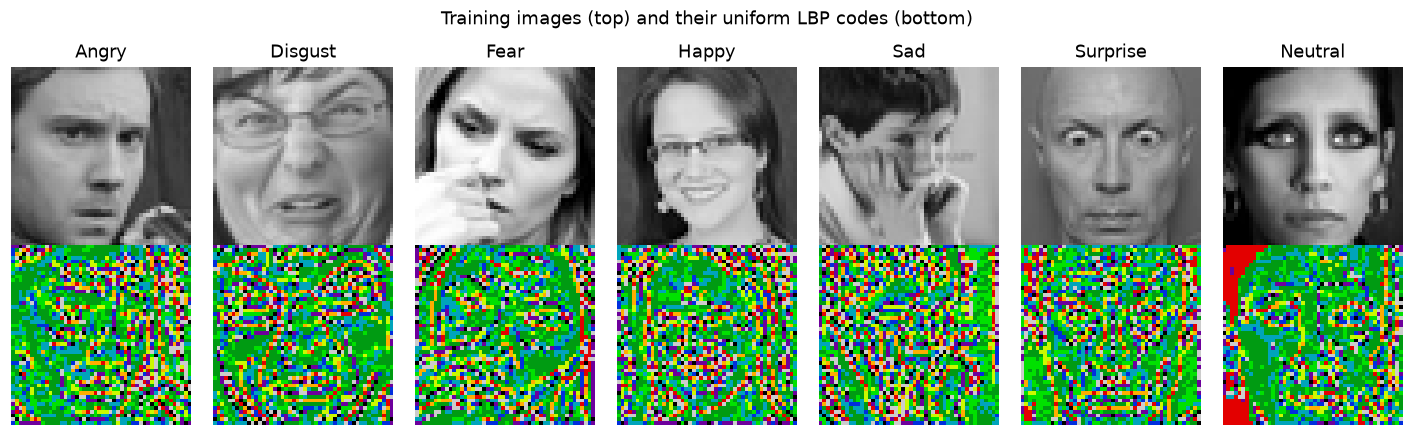

In [38]:
from skimage.feature import local_binary_pattern

T5_CACHE = DATA / 'feature_cache' / 'task5'
T5_CACHE.mkdir(parents=True, exist_ok=True)

# Finer HOG: 4x4-pixel cells give a 12x12 grid instead of 6x6 (4,356 instead of 900 values).
HOG_FINE_SETTINGS = {**HOG_SETTINGS, 'pixels_per_cell': (4, 4)}
# LBP: 8 neighbours at radius 1, 'uniform' codes (10 patterns), histograms on a 6x6 grid.
LBP_SETTINGS = {'P': 8, 'R': 1, 'method': 'uniform', 'grid_cell': 8}

def hog_fine(image):
    return hog(image.astype(np.float32) / 255.0, **HOG_FINE_SETTINGS)

def lbp_histograms(image):
    codes = local_binary_pattern(image, LBP_SETTINGS['P'], LBP_SETTINGS['R'], LBP_SETTINGS['method'])
    bins, cell = LBP_SETTINGS['P'] + 2, LBP_SETTINGS['grid_cell']
    return np.concatenate([
        np.bincount(codes[r:r + cell, c:c + cell].astype(int).ravel(), minlength=bins) / cell ** 2
        for r in range(0, 48, cell) for c in range(0, 48, cell)])

def cached_task5_features(kind, split, batch, extractor, settings):
    """Same caching scheme as Task 1: the key covers the dataset, split, settings, and library."""
    key = hashlib.sha256(json.dumps({'dataset': dataset_hash, 'kind': kind, 'split': split,
                                     'settings': settings,
                                     'skimage': importlib.metadata.version('scikit-image')},
                                    sort_keys=True).encode()).hexdigest()[:16]
    file = T5_CACHE / f'{kind}_{split}_{key}.npy'
    if file.exists():
        result = np.load(file)
        print('Loaded:', file.name)
    else:
        start = perf_counter()
        result = np.stack([extractor(image) for image in batch]).astype(np.float32)
        np.save(file, result)
        print(f'Extracted {kind}/{split}: {result.shape}, {perf_counter()-start:.1f}s')
    assert result.shape[0] == len(batch) and np.isfinite(result).all()
    return result

for split in ['train', 'validation']:
    features.setdefault('hog_fine', {})[split] = cached_task5_features(
        'hog_fine', split, images[split], hog_fine, HOG_FINE_SETTINGS)
    features.setdefault('lbp', {})[split] = cached_task5_features(
        'lbp', split, images[split], lbp_histograms, LBP_SETTINGS)

# What LBP sees: each pixel's code describes its local texture pattern.
fig, axes = plt.subplots(2, 7, figsize=(13, 4))
for label, (top, bottom) in enumerate(zip(axes[0], axes[1])):
    image = images['train'][np.flatnonzero(y['train'] == label)[0]]
    top.imshow(image, cmap='gray', vmin=0, vmax=255)
    bottom.imshow(local_binary_pattern(image, LBP_SETTINGS['P'], LBP_SETTINGS['R'],
                                       LBP_SETTINGS['method']), cmap='nipy_spectral')
    top.set_title(EMOTIONS[label])
for ax in axes.flat:
    ax.axis('off')
fig.suptitle('Training images (top) and their uniform LBP codes (bottom)')
plt.tight_layout()
plt.show()

In [39]:
# Reference model: the balanced Random Forest selected in 5.2, with the Task 1 settings.
reference_rf = clone(joblib.load('models/task1/hog_random_forest.pkl')['classifier']).set_params(
    class_weight='balanced')

def evaluate_feature_set(blocks):
    X_train = np.hstack([features[block]['train'] for block in blocks])
    X_validation = np.hstack([features[block]['validation'] for block in blocks])
    model = clone(reference_rf)
    start = perf_counter()
    model.fit(X_train, y['train'])
    fit_seconds = perf_counter() - start
    predictions = model.predict(X_validation)
    print(f'{" + ".join(blocks)}: {X_train.shape[1]} features, fitted in {fit_seconds:.1f}s', flush=True)
    return {'features': ' + '.join(blocks), 'n_features': X_train.shape[1],
            **metric_scores(y['validation'], predictions), 'fit_seconds': fit_seconds}

# Every combination of the three blocks: the forest samples sqrt(n_features) candidates per
# split, so adding a large block can crowd out a smaller, more useful one.
feature_sets = [['hog'], ['hog_fine'], ['lbp'], ['hog', 'hog_fine'], ['hog', 'lbp'],
                ['hog', 'hog_fine', 'lbp']]
feature_results = pd.DataFrame([evaluate_feature_set(blocks) for blocks in feature_sets])
best_feature_set = feature_results.loc[feature_results.macro_f1.idxmax(), 'features'].split(' + ')
display(feature_results.round(4))
print('Best feature set on validation:', ' + '.join(best_feature_set))

hog: 900 features, fitted in 26.6s
hog_fine: 4356 features, fitted in 45.8s
lbp: 360 features, fitted in 4.0s
hog + hog_fine: 5256 features, fitted in 56.1s
hog + lbp: 1260 features, fitted in 27.0s
hog + hog_fine + lbp: 5616 features, fitted in 58.5s


,features,n_features,accuracy,balanced_accuracy,macro_f1,fit_seconds
0,hog,900,0.4625,0.4363,0.4325,26.5583
1,hog_fine,4356,0.4452,0.4101,0.4259,45.7552
2,lbp,360,0.3695,0.3538,0.3681,4.0092
3,hog + hog_fine,5256,0.4609,0.4247,0.4355,56.1356
4,hog + lbp,1260,0.4698,0.4463,0.4429,27.0142
5,hog + hog_fine + lbp,5616,0.4650,0.4282,0.4366,58.4680


Best feature set on validation: hog + lbp


Combining HOG with LBP gives the best validation result. Macro-F1 rises from 0.433 to 0.443, and accuracy (0.470) and balanced accuracy (0.446) also improve:

| Features | Number of features | Macro-F1 |
|---|---:|---:|
| HOG (8×8 cells) | 900 | 0.433 |
| Finer HOG (4×4 cells) | 4,356 | 0.426 |
| LBP | 360 | 0.368 |
| HOG + finer HOG | 5,256 | 0.436 |
| **HOG + LBP** | **1,260** | **0.443** |
| HOG + finer HOG + LBP | 5,616 | 0.437 |

LBP alone is weak, but it complements HOG: HOG describes the outlines of the face (edge directions), while LBP adds local texture. The finer HOG did not help, either alone or in combination. With 4×4-pixel cells, each cell covers only 16 pixels of a low-resolution image, so its gradients are dominated by noise. The size of the block matters too. A Random Forest considers only √(number of features) randomly chosen features at each split, so the 4,356 fine-HOG values crowd out the 360 more useful LBP values. Adding LBP to HOG improves the score by 0.010, while adding it to HOG + finer HOG improves it by only 0.001. We therefore continue with HOG + LBP, which is also the faster combination to compute for the real-time demo in Task 6.

#### Shape features: landmarks and KDEF-derived geometric features
HOG and LBP describe what the face *looks like*. We now add features that describe its *shape*:

- **Landmarks:** the 136 normalised dlib landmark coordinates from Task 1 (section 1.3).
- **Geometric features:** the seven measurements designed and validated on KDEF in Task 4 (section 4.2): mouth opening, mouth width, lip-corner lift, eye opening, inner-brow raise, brow slant and inner-brow gap. This tests whether insights gained on KDEF transfer to FER2013.

The Task 1 landmark features scale x and y separately, which distorts distances. The geometric features are therefore computed from the raw landmark points, using the same predictor and face box as Task 1. Section 4.2 must be run first, because it defines `t4_geometric_features`.

In [40]:
# Shape features: the 136 Task 1 landmark values, and Task 4's seven geometric measurements.
# The Task 1 landmarks scale x and y separately, which distorts distances, so the geometric
# features are computed from the raw landmark points instead (same predictor and face box).
assert 't4_geometric_features' in globals(), 'Run section 4.2 first: it defines t4_geometric_features.'
LANDMARK_SETTINGS = {'predictor': predictor_hash, 'rectangle': [1, 1, 47, 47]}
for split in ['train', 'validation']:
    points = cached_task5_features('landmark_points', split, images[split], landmark_points,
                                   LANDMARK_SETTINGS)
    features.setdefault('geometric', {})[split] = np.array(
        [list(t4_geometric_features(p).values()) for p in points], dtype=np.float32)
    assert np.isfinite(features['geometric'][split]).all()

# Do the KDEF findings hold on FER? Same per-emotion medians as in 4.2, now on FER training images.
display(pd.DataFrame(features['geometric']['train'], columns=T4_FEATURES)
        .groupby(np.array(EMOTIONS)[y['train']]).median().reindex(EMOTIONS).round(3))

shape_sets = [best_feature_set, best_feature_set + ['landmarks'], best_feature_set + ['geometric'],
              best_feature_set + ['landmarks', 'geometric']]
shape_results = pd.DataFrame([evaluate_feature_set(blocks) for blocks in shape_sets])
best_feature_set = shape_results.loc[shape_results.macro_f1.idxmax(), 'features'].split(' + ')
display(shape_results.round(4))
print('Best feature set on validation:', ' + '.join(best_feature_set))

Loaded: landmark_points_train_f6335e25bdf64799.npy
Loaded: landmark_points_validation_20abc3cd0432074e.npy


,mouth_open,mouth_width,lip_corner_lift,eye_open,inner_brow_raise,brow_slant,inner_brow_gap
Angry,0.087,0.811,0.059,0.305,0.225,0.028,0.360
Disgust,0.072,0.824,0.058,0.281,0.222,0.017,0.361
Fear,0.078,0.814,0.058,0.331,0.251,0.049,0.372
Happy,0.145,0.955,0.123,0.291,0.249,0.043,0.392
Sad,0.063,0.811,0.055,0.313,0.248,0.032,0.356
Surprise,0.118,0.745,0.042,0.385,0.271,0.069,0.396
Neutral,0.051,0.790,0.048,0.328,0.249,0.031,0.370


hog + lbp: 1260 features, fitted in 26.7s
hog + lbp + landmarks: 1396 features, fitted in 30.1s
hog + lbp + geometric: 1267 features, fitted in 27.3s
hog + lbp + landmarks + geometric: 1403 features, fitted in 28.6s


,features,n_features,accuracy,balanced_accuracy,macro_f1,fit_seconds
0,hog + lbp,1260,0.4698,0.4463,0.4429,26.6529
1,hog + lbp + landmarks,1396,0.4890,0.4640,0.4657,30.0790
2,hog + lbp + geometric,1267,0.4968,0.4677,0.4721,27.2796
3,hog + lbp + landmarks + geometric,1403,0.4898,0.4658,0.4665,28.5858


Best feature set on validation: hog + lbp + geometric


The seven KDEF-derived geometric features give the largest single improvement in this section. Macro-F1 rises from 0.443 to **0.472**, and accuracy from 0.470 to 0.497:

| Features | Number of features | Accuracy | Macro-F1 |
|---|---:|---:|---:|
| HOG + LBP | 1,260 | 0.470 | 0.443 |
| HOG + LBP + landmarks | 1,396 | 0.489 | 0.466 |
| **HOG + LBP + geometric** | **1,267** | **0.497** | **0.472** |
| HOG + LBP + landmarks + geometric | 1,403 | 0.490 | 0.467 |

The geometric features are computed from the same landmark points as the 136 landmark values, yet they help more. A Random Forest splits on one feature at a time, so it cannot easily derive a distance between two landmarks, such as mouth width, from their separate x and y coordinates. The geometric features provide these distances directly, already corrected for face size and head tilt. Adding the 136 landmark values to the geometric features makes the result slightly worse (0.467). They carry mostly the same information and dilute the forest's random feature choices, as the finer HOG did above.

The per-emotion medians show which KDEF insights transfer to FER2013. The mouth and eye features behave as on KDEF: Happy has the widest mouth and most lifted lip corners, and Surprise has the most open eyes, a wide-open mouth and the narrowest mouth width. The brow features transfer poorly. On KDEF, Angry had clearly lowered brows (inner_brow_raise 0.101 against about 0.2–0.26 for the other emotions), but on FER2013 Angry (0.225) is close to the other emotions. Brow movements span only one or two pixels in a 48×48 image, which is below what the landmark predictor can locate reliably. The geometric features therefore help mainly through the mouth and eyes.

We continue with **HOG + LBP + geometric features** (macro-F1 0.472 on validation).

### 5.5. Hyperparameter Tuning
All experiments so far used the Task 1 classifier settings. On the final feature set (HOG + LBP + geometric), we now tune the classifiers and re-check the choice of classifier. The Task 1 ranking was close, and the features have changed since then. All models are trained on Training and compared on PublicTest by macro-F1:

- **Random Forest** (balanced, 300 trees): maximum depth 11 (Task 1) or unlimited, and a minimum of 1, 3 or 5 training images per leaf. Larger leaves stop the trees from splitting down to single, possibly noisy, images.
- **Logistic Regression**: regularisation strength `C` ∈ {0.01, 0.1, 1}, with and without class balancing, because 5.2 only tested balancing on HOG.
- **Linear SVM**: `C` ∈ {0.001, 0.01, 0.1}.
The full search takes about 10 minutes.

In [ ]:
# Tune on the feature set selected in 5.4. Fitted models are not kept: the selected
# configuration is refitted once when it is frozen in 5.6.
X_tune = {split: np.hstack([features[block][split] for block in best_feature_set])
          for split in ['train', 'validation']}
print('Features:', ' + '.join(best_feature_set), X_tune['train'].shape)

def make_model(classifier, settings):
    if classifier == 'Random Forest':  # balanced, as selected in 5.2
        return clone(reference_rf).set_params(**settings)
    if classifier == 'Logistic Regression':
        return make_pipeline(StandardScaler(), LogisticRegression(**settings, max_iter=3000,
                                                                  random_state=SEED))
    if classifier == 'Linear SVM':
        return make_pipeline(StandardScaler(), LinearSVC(**settings, dual=False, max_iter=10000,
                                                         random_state=SEED))
    raise ValueError(classifier)

def evaluate_model(classifier, settings):
    model = make_model(classifier, settings)
    start = perf_counter()
    model.fit(X_tune['train'], y['train'])
    fit_seconds = perf_counter() - start
    scores = metric_scores(y['validation'], model.predict(X_tune['validation']))
    print(f'{classifier} {settings}: macro-F1 {scores["macro_f1"]:.4f} ({fit_seconds:.0f}s)', flush=True)
    return {'classifier': classifier, 'settings': settings, **scores, 'fit_seconds': fit_seconds}

tuning_rows = []
# Random Forest (300 trees): depth (Task 1 capped it at 11) and minimum images per leaf.
for max_depth in [11, None]:
    for min_samples_leaf in [1, 3, 5]:
        tuning_rows.append(evaluate_model('Random Forest',
                                          {'max_depth': max_depth, 'min_samples_leaf': min_samples_leaf}))
# Linear models: regularisation strength, and class weighting again on the new features.
for C in [0.01, 0.1, 1.0]:
    for class_weight in [None, 'balanced']:
        tuning_rows.append(evaluate_model('Logistic Regression',
                                          {'C': C, 'class_weight': class_weight}))
for C in [0.001, 0.01, 0.1]:
    tuning_rows.append(evaluate_model('Linear SVM', {'C': C}))

tuning_results = pd.DataFrame(tuning_rows).assign(settings=lambda d: d.settings.astype(str))
display(tuning_results.sort_values('macro_f1', ascending=False).round(4))
best_index = tuning_results.macro_f1.idxmax()
best_tuning, best_settings = tuning_results.loc[best_index], tuning_rows[best_index]['settings']
print(f'Best on validation: {best_tuning.classifier} {best_settings} '
      f'(macro-F1 {best_tuning.macro_f1:.4f})')

**The tuned balanced Random Forest is the best configuration:** macro-F1 **0.490** and accuracy **0.514** on PublicTest. The best configuration of each classifier:

| Classifier | Best settings | Accuracy | Balanced accuracy | Macro-F1 |
|---|---|---:|---:|---:|
| **Random Forest** | balanced, 300 trees, unlimited depth, ≥ 3 images per leaf | **0.514** | **0.469** | **0.490** |
| Logistic Regression | `C` = 0.1, no class weighting | 0.481 | 0.447 | 0.452 |
| Linear SVM | `C` = 0.01 | 0.487 | 0.436 | 0.442 |

Removing the depth limit improved the Random Forest from 0.472 to 0.480, and requiring at least three training images per leaf raised it further to 0.490. With unlimited depth, each tree can learn the combinations of HOG, LBP and geometric features that separate similar expressions. Very small leaves, however, let a tree memorise individual training images. Some FER2013 images are ambiguous or mislabelled, so memorising them adds noise. A minimum of three images per leaf removes these splits, and five per leaf (0.486) starts to remove useful detail.

The Random Forest clearly outperforms the linear models (0.490 against 0.442–0.452). On HOG alone in Task 1, the three classifiers were within about 0.02 of each other. A likely reason is that the geometric features interact non-linearly. A wide mouth means Happy only together with lifted lip corners, and an open mouth means Surprise only together with wide-open eyes. Trees can represent such combinations, but a linear model can only add up the features' separate contributions.

Class weighting again lowers macro-F1 for Logistic Regression (0.452 → 0.422), consistent with 5.2. Of the three classifiers, only the Random Forest benefits from balancing.

These configurations were all compared on the same validation set, so the best score is slightly optimistic. The selected model's real performance is measured once on PrivateTest.

### 5.6. Freeze the Final Model and Evaluate PrivateTest
We freeze the configuration selected on PublicTest: **HOG + LBP + geometric features with the tuned balanced Random Forest** (300 trees, unlimited depth, at least 3 images per leaf). The decision and the validation scores of every accepted step are saved to `results/task5/` *before* PrivateTest is touched. Like Task 1, the model is trained on Training only, so the comparison with the Task 1 baseline is fair.

The feature extraction now lives in `src/fer_features.py`, so the real-time demo (Task 6) can compute exactly the same features. The cell below checks that this module reproduces the notebook's features. PrivateTest features are computed with the module, the same code path the demo uses. PrivateTest is evaluated once, and the result is not used to change any choice.

In [43]:
import importlib

import src.fer_features as fer_features
importlib.reload(fer_features)  # picks up edits to the module without restarting the kernel

T5_OUT = ROOT / 'results' / 'task5'
T5_MODELS = ROOT / 'models' / 'task5'
for folder in [T5_OUT, T5_MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

# The configuration selected on PublicTest in 5.4 and 5.5.
final_model = make_model(best_tuning.classifier, best_settings)
final_name = f'{"_".join(best_feature_set)}_{best_tuning.classifier.lower().replace(" ", "_")}'
print('Frozen:', ' + '.join(best_feature_set), '|', best_tuning.classifier, best_settings)

# Validation scores of each accepted step, collected from the experiments above.
SCORES = ['accuracy', 'balanced_accuracy', 'macro_f1']
validation_progression = pd.DataFrame([
    {'step': '5.1 Task 1 selection: HOG + Logistic Regression',
     **balancing_results.query("classifier == 'Logistic Regression' and class_weight == 'none'").iloc[0][SCORES].to_dict()},
    {'step': '5.2 class balancing: HOG + balanced Random Forest',
     **balancing_results.query("classifier == 'Random Forest' and class_weight == 'balanced'").iloc[0][SCORES].to_dict()},
    {'step': '5.4 + LBP texture features',
     **feature_results.query("features == 'hog + lbp'").iloc[0][SCORES].to_dict()},
    {'step': '5.4 + KDEF-derived geometric features',
     **shape_results.query("features == 'hog + lbp + geometric'").iloc[0][SCORES].to_dict()},
    {'step': f'5.5 tuning: {best_tuning.classifier} {best_settings}', **best_tuning[SCORES].to_dict()},
])
validation_progression.to_csv(T5_OUT / 'validation_progression.csv', index=False)
display(validation_progression.round(4))

# Freeze the decision before PrivateTest is touched.
selection = {
    'selection_split': 'PublicTest', 'selection_metric': 'macro_f1', 'training_split': 'Training',
    'features': best_feature_set,
    'feature_settings': {'hog': fer_features.HOG_SETTINGS, 'lbp': fer_features.LBP_SETTINGS,
                         'geometric': fer_features.GEOMETRIC_FEATURES,
                         'landmark_rectangle': list(fer_features.LANDMARK_RECTANGLE)},
    'classifier': best_tuning.classifier,
    'parameters': {key: str(value) for key, value in final_model.get_params().items()},
    'validation_scores': best_tuning[SCORES].to_dict(),
    'rejected': ['class balancing for the linear models (5.2, 5.5)',
                 'mirroring augmentation (5.3)', 'finer HOG (5.4)', 'landmark coordinates (5.4)'],
    'seed': SEED, 'dataset_sha256': dataset_hash,
}
(T5_OUT / 'frozen_selection.json').write_text(json.dumps(selection, indent=2), encoding='utf-8')

final_model.fit(X_tune['train'], y['train'])
final_validation = metric_scores(y['validation'], final_model.predict(X_tune['validation']))
assert np.isclose(final_validation['macro_f1'], best_tuning.macro_f1), 'Refit did not reproduce 5.5.'
print(f'Refitted; validation macro-F1 {final_validation["macro_f1"]:.4f}')

# The demo computes features with src/fer_features.py, so it must match the notebook exactly.
extractor = fer_features.FeatureExtractor(PREDICTOR)
assert np.allclose(extractor.transform(images['validation'][:300]), X_tune['validation'][:300], atol=1e-6)
print('The shared feature extractor reproduces the notebook features.')

Frozen: hog + lbp + geometric | Random Forest {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 600}


,step,accuracy,balanced_accuracy,macro_f1
0,5.1 Task 1 selection: HOG + Logistic Regression,0.4363,0.4021,0.4000
1,5.2 class balancing: HOG + balanced Random Forest,0.4625,0.4363,0.4325
2,5.4 + LBP texture features,0.4698,0.4463,0.4429
3,5.4 + KDEF-derived geometric features,0.4968,0.4677,0.4721
4,"5.5 tuning: Random Forest {'max_depth': None, ...",0.5277,0.4731,0.4943


Refitted; validation macro-F1 0.4943
The shared feature extractor reproduces the notebook features.


In [ ]:
# Evaluate PrivateTest once, using the frozen model and the same extractor as the demo.
FEATURE_NAMES = {'hog': 'HOG', 'lbp': 'LBP', 'geometric': 'geometric'}
final_label = f'Task 5: {" + ".join(FEATURE_NAMES[b] for b in best_feature_set)}, {best_tuning.classifier}'
images['test'] = decode_images(split_frames['test'])
start = perf_counter()
X_test = extractor.transform(images['test'])
print(f'Test features: {X_test.shape}, {1000 * (perf_counter() - start) / len(X_test):.1f} ms per image')
final_test_predictions = final_model.predict(X_test)
final_test = metric_scores(y['test'], final_test_predictions)

baseline_test = pd.read_csv(ROOT / 'results/task1/test_results.csv').query(
    "feature == 'hog' and classifier == 'Logistic Regression'").iloc[0]
test_comparison = pd.DataFrame([
    {'model': 'Task 1: HOG + Logistic Regression', **baseline_test[SCORES].to_dict()},
    {'model': final_label, **final_test},
])
test_comparison.to_csv(T5_OUT / 'test_results.csv', index=False)
display(test_comparison.round(4))

baseline_report = pd.read_csv(ROOT / 'results/task1/selected_test_classification_report.csv', index_col=0)
final_report = pd.DataFrame(classification_report(
    y['test'], final_test_predictions, labels=LABELS, target_names=EMOTIONS,
    output_dict=True, zero_division=0)).T
final_report.to_csv(T5_OUT / 'test_classification_report.csv')
per_class_f1 = pd.DataFrame({'Task 1 F1': baseline_report.loc[EMOTIONS, 'f1-score'],
                             'Task 5 F1': final_report.loc[EMOTIONS, 'f1-score']})
per_class_f1['change'] = per_class_f1['Task 5 F1'] - per_class_f1['Task 1 F1']
display(per_class_f1.round(3))

final_counts = confusion_matrix(y['test'], final_test_predictions, labels=LABELS)
np.savetxt(T5_OUT / 'test_confusion_counts.csv', final_counts, delimiter=',', fmt='%d')
pd.DataFrame({'split_row_index': np.arange(len(final_test_predictions)), 'actual': y['test'],
              'predicted': final_test_predictions}).to_csv(T5_OUT / 'test_predictions.csv', index=False)
baseline_counts = np.loadtxt(ROOT / 'results/task1/test_hog_logistic_regression_confusion_counts.csv',
                             delimiter=',')
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, counts, title in [(axes[0], baseline_counts, 'Task 1: HOG + Logistic Regression'),
                          (axes[1], final_counts, final_label)]:
    ConfusionMatrixDisplay(counts / counts.sum(axis=1, keepdims=True), display_labels=EMOTIONS).plot(
        ax=ax, cmap='Blues', values_format='.2f', colorbar=False, xticks_rotation=45)
    ax.set_title(title)
fig.suptitle('PrivateTest confusion matrices, row-normalised (recall)')
plt.tight_layout()
fig.savefig(T5_OUT / 'test_confusion_matrices.png', dpi=160, bbox_inches='tight')
plt.show()

In [ ]:
# Save the model with everything needed to recreate its input (used by the Task 6 demo).
final_bundle = {
    'classifier': final_model, 'classifier_name': best_tuning.classifier, 'settings': best_settings,
    'feature_extractor': 'src.fer_features.FeatureExtractor',
    'features': best_feature_set, 'n_features': X_tune['train'].shape[1],
    'hog_settings': fer_features.HOG_SETTINGS, 'lbp_settings': fer_features.LBP_SETTINGS,
    'geometric_features': fer_features.GEOMETRIC_FEATURES,
    'landmark_predictor': str(PREDICTOR.relative_to(ROOT)), 'landmark_predictor_sha256': predictor_hash,
    'landmark_rectangle': list(fer_features.LANDMARK_RECTANGLE),
    'image_shape': (48, 48), 'input_dtype': 'uint8', 'input_range': [0, 255],
    'emotion_names': EMOTIONS, 'seed': SEED,
    'validation_scores': final_validation, 'test_scores': final_test,
}
joblib.dump(final_bundle, T5_MODELS / f'{final_name}.pkl', compress=3)
t5_versions = {name: importlib.metadata.version(name) for name in
               ['numpy', 'pandas', 'scikit-learn', 'scikit-image', 'matplotlib', 'joblib']}
t5_versions['dlib'] = dlib.__version__
t5_versions['python'] = sys.version
(T5_OUT / 'versions.json').write_text(json.dumps(t5_versions, indent=2), encoding='utf-8')
print(f'Model: {(T5_MODELS / f"{final_name}.pkl").relative_to(ROOT)}, '
      f'{(T5_MODELS / f"{final_name}.pkl").stat().st_size / 1e6:.0f} MB')
print('Tables and figures:', T5_OUT.relative_to(ROOT))

**Final PrivateTest results.** The Task 5 model improves on the Task 1 baseline on every metric:

| Model | Accuracy | Balanced accuracy | Macro-F1 |
|---|---:|---:|---:|
| Task 1: HOG + Logistic Regression | 0.433 | 0.404 | 0.397 |
| **Task 5: HOG + LBP + geometric, balanced Random Forest** | **0.515** | **0.469** | **0.489** |

Macro-F1 rises by 0.09 and accuracy by 0.08. The test score (0.489) is almost identical to the validation score (0.490), so the many choices made on PublicTest did not noticeably overfit that split.

Every emotion's F1 improved. The largest gains are for Surprise (+0.18) and Disgust (+0.13), and the smallest for Happy and Sad (+0.05 each). Recall improved for every emotion except Disgust (0.40 → 0.35). However, the model predicts Disgust only 20 times on the test set, and 19 of those predictions are correct (precision 0.95), so Disgust F1 still rose from 0.38 to 0.51. Even with class balancing, the forest predicts the rare class cautiously, only for clear cases.

The confusion matrix shows what remains difficult. The model predicts Happy (1,180 predictions for 879 images) and Neutral (786 for 626) too often, and Angry (306 for 491) and Fear (320 for 528) too rarely. Ambiguous faces are pulled towards the frequent and visually distinctive classes. Fear is the hardest emotion (recall 0.26): it is spread over Neutral (20%), Sad (19%) and Happy (18%). Sad is most often predicted as Neutral (24%) or Happy (22%). These emotions differ mainly in subtle brow and mouth movements, which are hard to capture at 48×48 pixels.

Computing the features and predicting takes about 15 ms per 48×48 face, which is fast enough for the real-time demo.

## 6. Run your models in a real-time a real-time emotion recognition program with your laptop (10%)